# 1. Data Understanding

## 1.1 Setting Up

In [1]:
# Import libraries
import re

import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

# Set constants
FIGURES_PATH = "../reports/figures"
TABLES_PATH = "../reports/tables"
RAW_DATA_PATH = "../data/raw"
TXT_FILES = "../data/txt"
PROCESSED_DATA_PATH = "../data/processed"

In [2]:
# Define the path to the data file
path = "../data/raw/mental-heath-in-tech-2016_20161114.csv"

print(f"We will load data from: '{path}'")

We will load data from: '../data/raw/mental-heath-in-tech-2016_20161114.csv'


In [3]:
# Load the dataset
(pd.read_csv(path))

,Are you self-employed?,How many employees does your company or organization have?,Is your employer primarily a tech company/organization?,Is your primary role within your company related to tech/IT?,Does your employer provide mental health benefits as part of healthcare coverage?,Do you know the options for mental health care available under your employer-provided coverage?,"Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?",Does your employer offer resources to learn more about mental health concerns and options for seeking help?,Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?,"If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",...,"If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?","If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?",What is your age?,What is your gender?,What country do you live in?,What US state or territory do you live in?,What country do you work in?,What US state or territory do you work in?,Which of the following best describes your work position?,Do you work remotely?
0,0,26-100,1.0,NaN,Not eligible for coverage / N/A,NaN,No,No,I don't know,Very easy,...,Not applicable to me,Not applicable to me,39,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Sometimes
1,0,6-25,1.0,NaN,No,Yes,Yes,Yes,Yes,Somewhat easy,...,Rarely,Sometimes,29,male,United States of America,Illinois,United States of America,Illinois,Back-end Developer|Front-end Developer,Never
2,0,6-25,1.0,NaN,No,NaN,No,No,I don't know,Neither easy nor difficult,...,Not applicable to me,Not applicable to me,38,Male,United Kingdom,NaN,United Kingdom,NaN,Back-end Developer,Always
3,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Sometimes,Sometimes,43,male,United Kingdom,NaN,United Kingdom,NaN,Supervisor/Team Lead,Sometimes
4,0,6-25,0.0,1.0,Yes,Yes,No,No,No,Neither easy nor difficult,...,Sometimes,Sometimes,43,Female,United States of America,Illinois,United States of America,Illinois,Executive Leadership|Supervisor/Team Lead|Dev ...,Sometimes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1428,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Not applicable to me,Not applicable to me,34,Female,United States of America,New York,United States of America,New York,Other,Sometimes
1429,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Sometimes,Often,56,MALE,United States of America,California,Afghanistan,NaN,Support,Sometimes
1430,0,100-500,1.0,NaN,Yes,Yes,Yes,Yes,I don't know,Somewhat difficult,...,Rarely,Sometimes,52,Male,United States of America,Georgia,United States of America,Georgia,Back-end Developer,Sometimes
1431,0,100-500,0.0,1.0,I don't know,I am not sure,No,Yes,I don't know,Somewhat difficult,...,Sometimes,Often,30,Female,United States of America,Nebraska,United States of America,Nebraska,DevOps/SysAdmin,Sometimes


In [4]:
(pd.read_csv(path).columns.tolist())

['Are you self-employed?',
 'How many employees does your company or organization have?',
 'Is your employer primarily a tech company/organization?',
 'Is your primary role within your company related to tech/IT?',
 'Does your employer provide mental health benefits as part of healthcare coverage?',
 'Do you know the options for mental health care available under your employer-provided coverage?',
 'Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?',
 'Does your employer offer resources to learn more about mental health concerns and options for seeking help?',
 'Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?',
 'If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:',
 'Do you think that discussing a mental health disorder with your employer would have neg

In [5]:
# Export column names to a txt file
pd.read_csv(path).columns.to_series().to_csv(
    f"{RAW_DATA_PATH}/column_names.txt",
    index=False,
    header=False
)

## 1.2 Inpecting the Data

In [6]:
(pd.read_csv(path)).head().T

,0,1,2,3,4
Are you self-employed?,0,0,0,1,0
How many employees does your company or organization have?,26-100,6-25,6-25,NaN,6-25
Is your employer primarily a tech company/organization?,1.0,1.0,1.0,NaN,0.0
Is your primary role within your company related to tech/IT?,NaN,NaN,NaN,NaN,1.0
Does your employer provide mental health benefits as part of healthcare coverage?,Not eligible for coverage / N/A,No,No,NaN,Yes
...,...,...,...,...,...
What US state or territory do you live in?,NaN,Illinois,NaN,NaN,Illinois
What country do you work in?,United Kingdom,United States of America,United Kingdom,United Kingdom,United States of America
What US state or territory do you work in?,NaN,Illinois,NaN,NaN,Illinois
Which of the following best describes your work position?,Back-end Developer,Back-end Developer|Front-end Developer,Back-end Developer,Supervisor/Team Lead,Executive Leadership|Supervisor/Team Lead|Dev ...


In [7]:
(pd.read_csv(path)).shape

(1433, 63)

In [8]:
(pd.read_csv(path)).dtypes

Are you self-employed?                                                                 int64
How many employees does your company or organization have?                               str
Is your employer primarily a tech company/organization?                              float64
Is your primary role within your company related to tech/IT?                         float64
Does your employer provide mental health benefits as part of healthcare coverage?        str
                                                                                      ...   
What US state or territory do you live in?                                               str
What country do you work in?                                                             str
What US state or territory do you work in?                                               str
Which of the following best describes your work position?                                str
Do you work remotely?                                                 

In [9]:
(pd.read_csv(path)).isnull().sum()

Are you self-employed?                                                                  0
How many employees does your company or organization have?                            287
Is your employer primarily a tech company/organization?                               287
Is your primary role within your company related to tech/IT?                         1170
Does your employer provide mental health benefits as part of healthcare coverage?     287
                                                                                     ... 
What US state or territory do you live in?                                            593
What country do you work in?                                                            0
What US state or territory do you work in?                                            582
Which of the following best describes your work position?                               0
Do you work remotely?                                                                   0
Length: 63

In [10]:
(
    pd.read_csv(path).dtypes
    .value_counts()
    .rename_axis("Data Type")
    .reset_index(name="Count")
)

,Data Type,Count
0,str,56
1,int64,4
2,float64,3


## 1.3 Inspecting Missingness

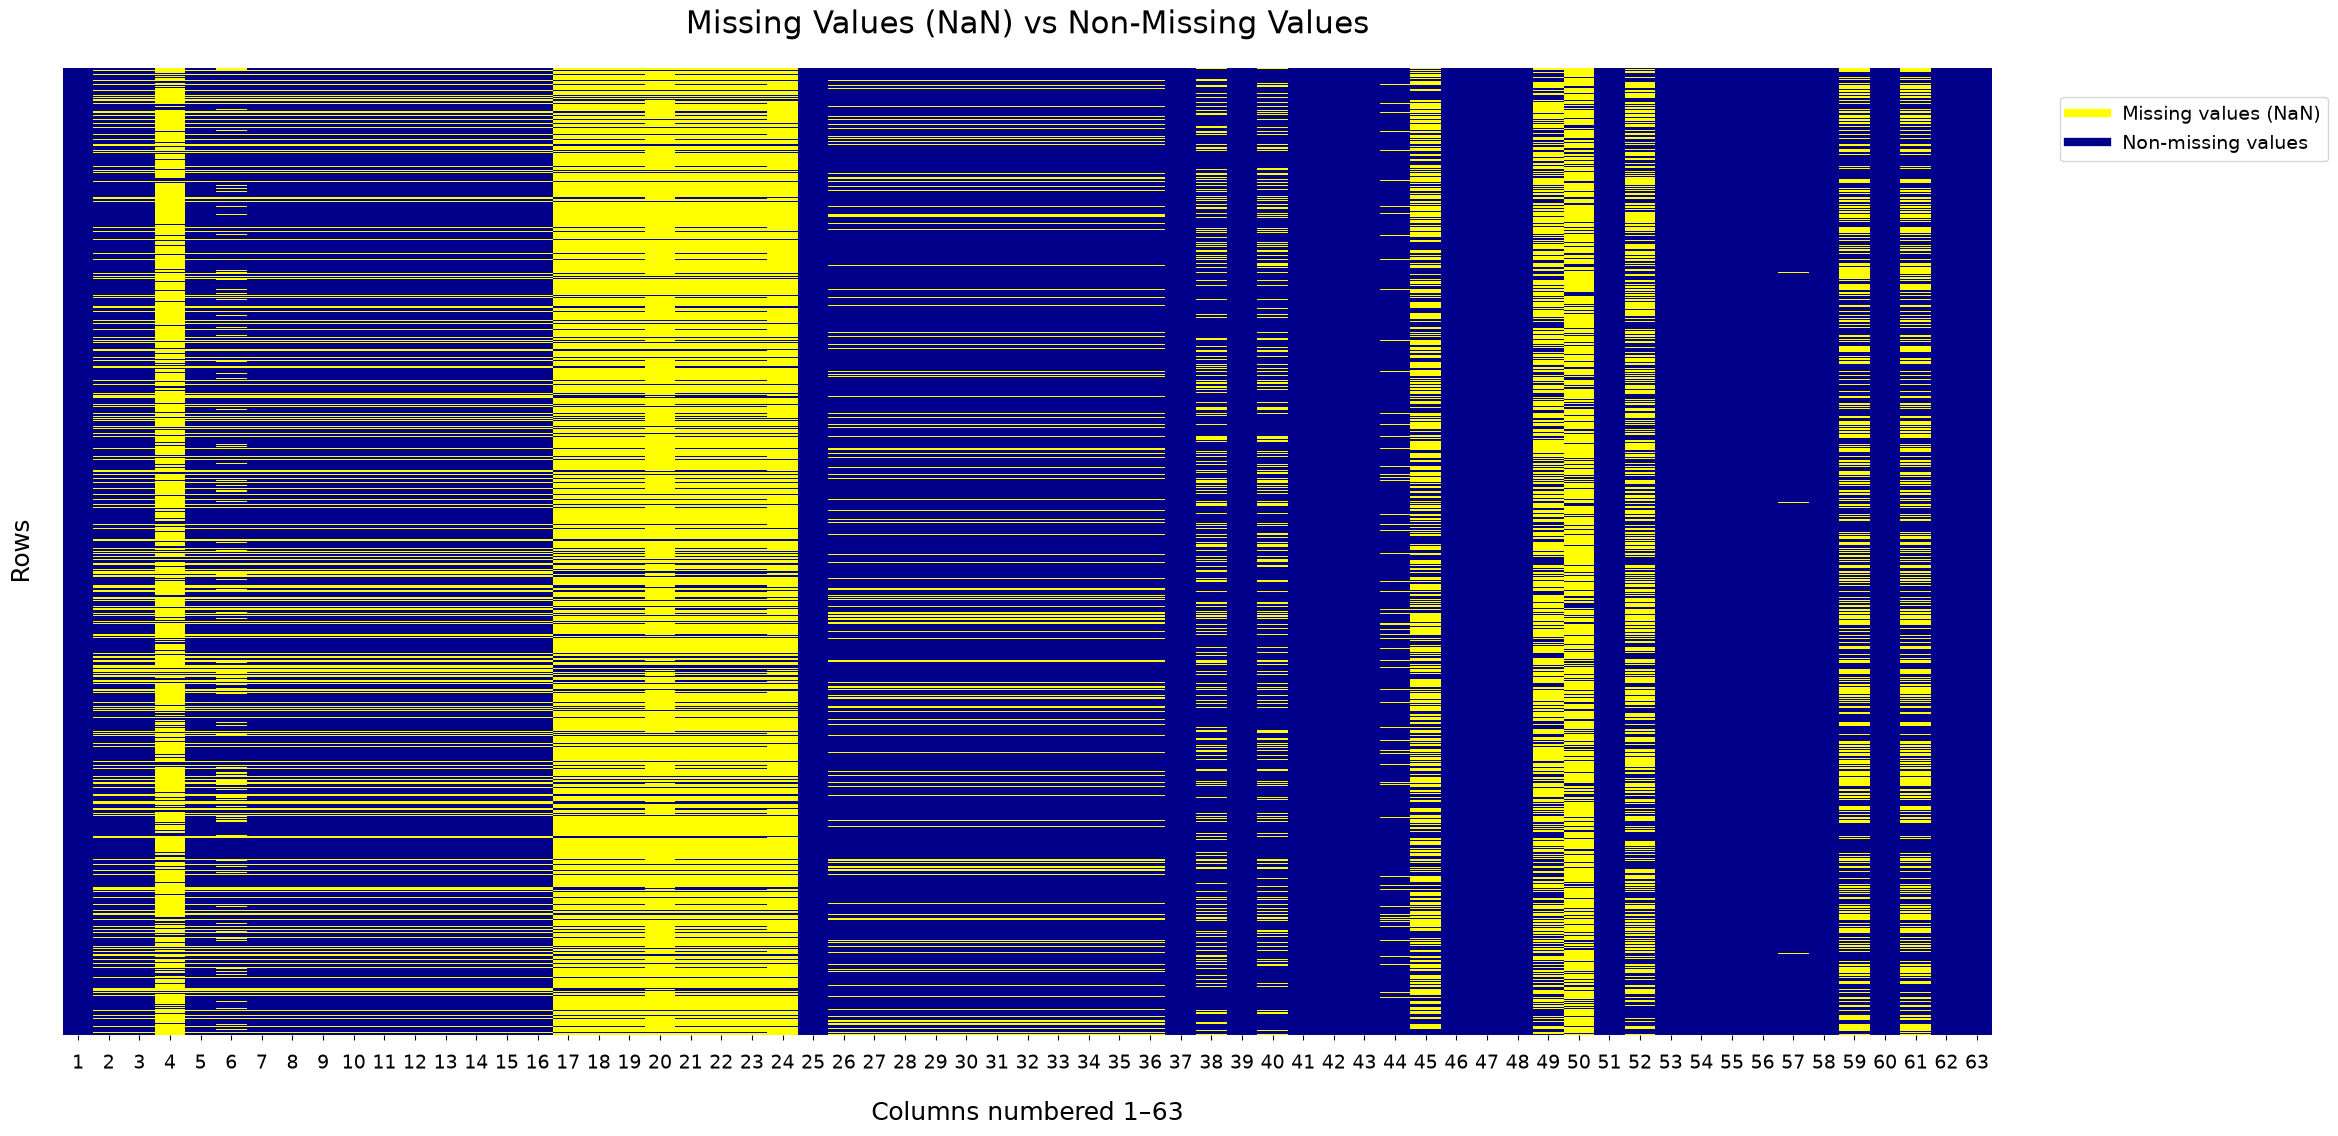

In [11]:
# Plot missing values by column
plt.figure(figsize=(24, 12))

sns.heatmap(
    (pd.read_csv(path).set_axis(range(1, 64), axis=1)).isnull(),
    cbar=False,
    cmap=sns.color_palette(["darkblue", "yellow"]),
    xticklabels=True,
    yticklabels=False,
)

plt.xlabel("Columns numbered 1–63", fontsize=18, labelpad=20)
plt.ylabel("Rows", fontsize=18, labelpad=20)
plt.title("Missing Values (NaN) vs Non-Missing Values", fontsize=22, pad=25)

plt.xticks(fontsize=14, rotation=0)
plt.yticks(fontsize=14)

plt.tick_params(axis="x", pad=10)
plt.tick_params(axis="y", pad=10)

plt.legend(
    handles=[
        plt.Line2D([0], [0], color="yellow", lw=6, label="Missing values (NaN)"),
        plt.Line2D([0], [0], color="darkblue", lw=6, label="Non-missing values"),
    ],
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=14,
    borderaxespad=1.5
)

plt.tight_layout(pad=3)
plt.savefig(
    f"{FIGURES_PATH}/missing_vs_non_missing.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

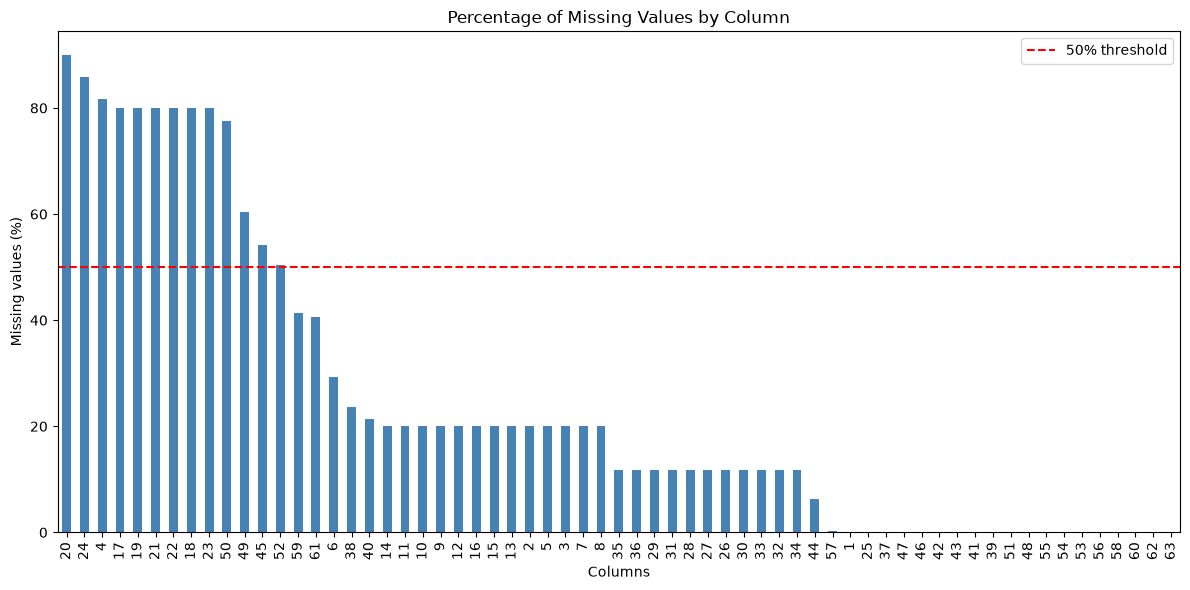

In [12]:
# Plot the percentage of missing values by column
(
    pd.read_csv(path)
    .set_axis(range(1, 64), axis=1)
    .isnull()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .plot(kind="bar", figsize=(12, 6), color="steelblue")
)

plt.axhline(50, color="red", linestyle="--", label="50% threshold")
plt.xlabel("Columns")
plt.ylabel("Missing values (%)")
plt.title("Percentage of Missing Values by Column")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.savefig(
    f"{FIGURES_PATH}/missingness_by_clumn.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In [13]:
# Display rows missing 50% or more of their values
pd.read_csv(path).loc[lambda df: df.isnull().mean(axis=1) >= 0.5]

,Are you self-employed?,How many employees does your company or organization have?,Is your employer primarily a tech company/organization?,Is your primary role within your company related to tech/IT?,Does your employer provide mental health benefits as part of healthcare coverage?,Do you know the options for mental health care available under your employer-provided coverage?,"Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?",Does your employer offer resources to learn more about mental health concerns and options for seeking help?,Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?,"If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",...,"If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?","If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?",What is your age?,What is your gender?,What country do you live in?,What US state or territory do you live in?,What country do you work in?,What US state or territory do you work in?,Which of the following best describes your work position?,Do you work remotely?
76,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Not applicable to me,Not applicable to me,19,M,France,NaN,France,NaN,Back-end Developer,Never
113,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Never,Sometimes,22,Male,Czech Republic,NaN,Czech Republic,NaN,Back-end Developer|Front-end Developer,Sometimes
340,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Not applicable to me,Not applicable to me,25,Male,United States of America,New York,United States of America,New York,Back-end Developer|Front-end Developer,Sometimes
450,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Not applicable to me,Not applicable to me,40,Male,Germany,NaN,Germany,NaN,Executive Leadership,Sometimes
511,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Not applicable to me,Not applicable to me,28,male,United States of America,California,United States of America,California,Other|Dev Evangelist/Advocate|One-person shop,Sometimes
546,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Sometimes,Sometimes,30,Male,United Kingdom,NaN,United Kingdom,NaN,Executive Leadership,Sometimes
563,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Not applicable to me,Not applicable to me,30,male,Poland,NaN,Poland,NaN,Supervisor/Team Lead|DevOps/SysAdmin|Back-end ...,Always
739,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Not applicable to me,Not applicable to me,31,Male,United States of America,Florida,United States of America,Florida,Executive Leadership,Sometimes
797,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Sometimes,Often,42,Fluid,United Kingdom,NaN,United States of America,California,DevOps/SysAdmin|Back-end Developer|Front-end D...,Always
808,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Not applicable to me,Not applicable to me,15,male,Canada,NaN,Canada,NaN,Other,Sometimes


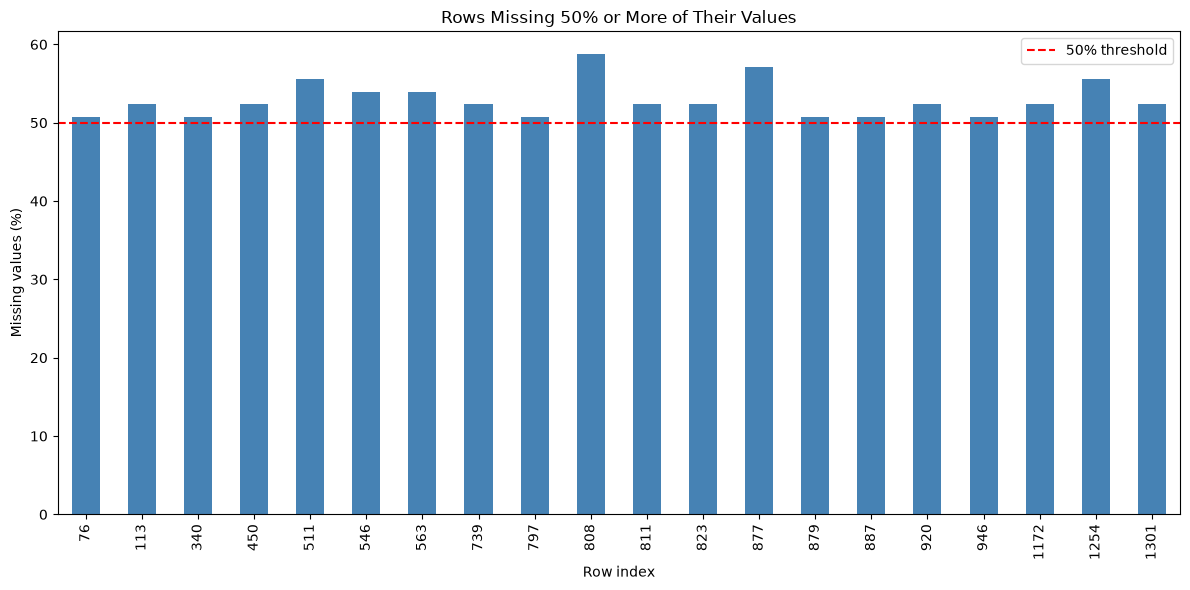

In [14]:
# Plot the percentage of missing values per row
(
    pd.read_csv(path)
    .isnull()
    .mean(axis=1)
    .mul(100)
    .loc[lambda x: x >= 50]
    .plot(kind="bar", figsize=(12, 6), color="steelblue")
)

plt.axhline(50, color="red", linestyle="--", label="50% threshold")
plt.xlabel("Row index")
plt.ylabel("Missing values (%)")
plt.title("Rows Missing 50% or More of Their Values")
plt.legend()
plt.tight_layout()
plt.savefig(
    f"{FIGURES_PATH}/row_missingness.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Raw Data Insights

As can be seen from the plots above, missingness in some of the rows and columns appears substantial in the raw state. How we will treat missingness in the cleaning pipeline is a two-step hierarchical process:

1. **Columns First:** We will drop the open-ended free-text columns and features with >50% missingness entirely. This eliminates the massive blocks of empty text fields that are skewing our row statistics. 
2. **Rows Second:** 
   - **Columns with 1%-5% missingness:** Columns with minimal missingness will be handled using simple imputation (such as filling missing categorical fields with the mode). Their rows will be dropped **if and only if they also represent completely corrupted, unrecoverable diagnostic entries (like an entirely empty row across core attributes).**
   - **Structural/Branching Missingness:** For rows missing data due to conditional survey routing (e.g., self-employed individuals missing corporate benefit questions), missing entries will be mapped to a structural `'Not Applicable'` category rather than being dropped.
   - **Skipped Questions:** Randomly omitted survey answers will be handled by introducing a distinct `'No Response'` category, preserving the 1,433-row sample size while treating question omission as an observable behavioral trait for our clustering models.


## 1.4 Inspecting Columns

| Column type | Examples | Visualization |
|---|---|---|
| Binary / Yes-No | Do you currently have a mental health disorder? | Count plot / bar chart |
| Categorical | Gender, country, work position | Bar chart |
| Ordinal | Company size, willingness to share | Ordered bar chart |
| Numerical | Age, percentage of work time affected | Histogram and box plot |
| Free text | Why or why not? | Missing-value analysis and text analysis |
| Conditional responses | What conditions have you been diagnosed with? | Value counts, including missing values |

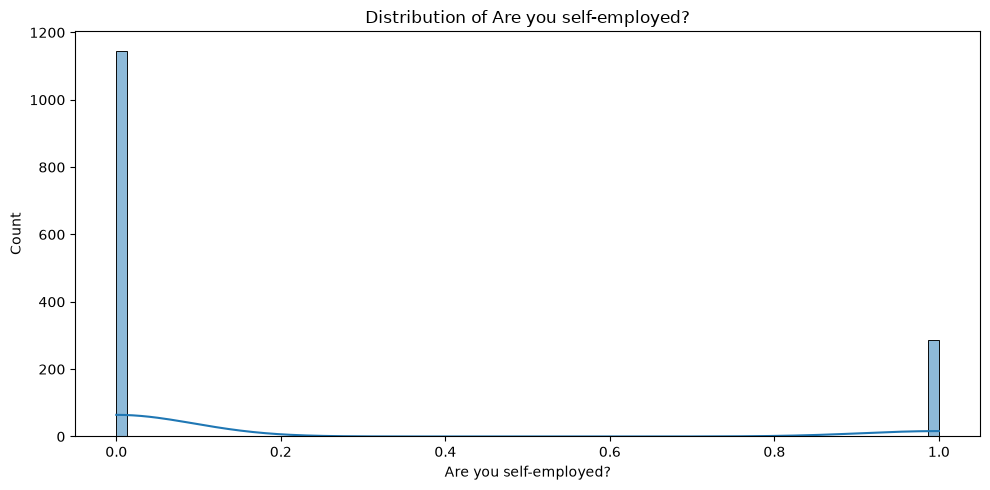

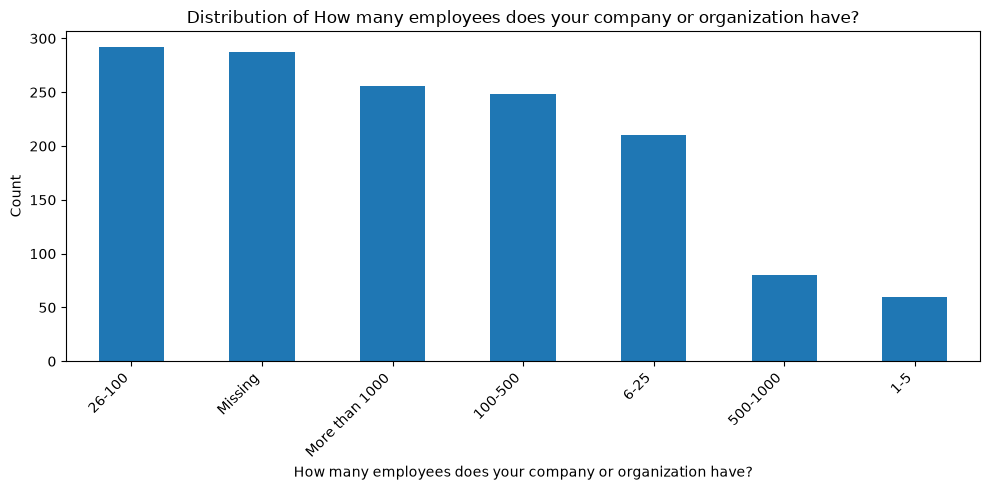

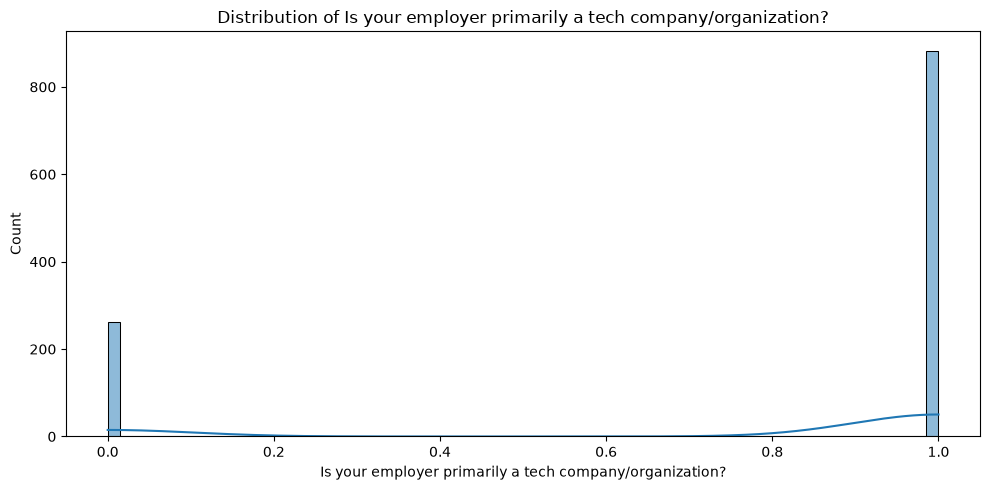

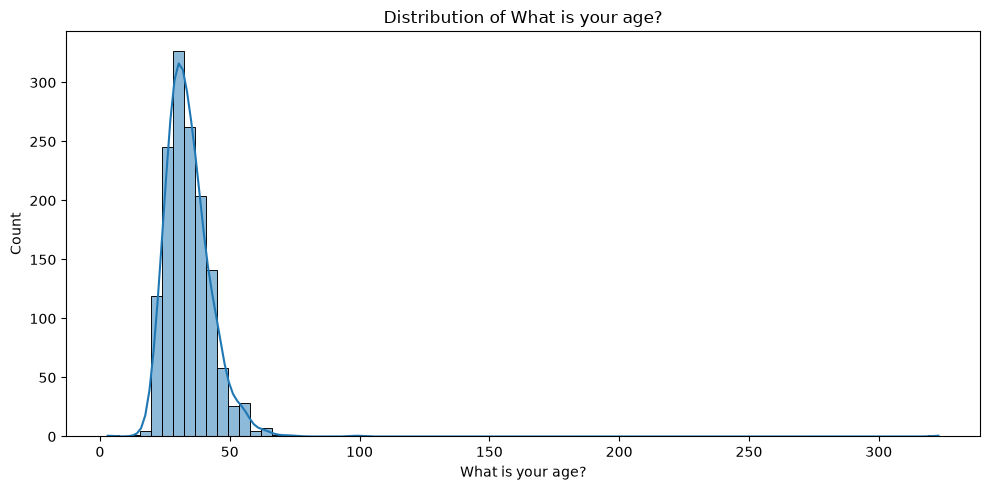

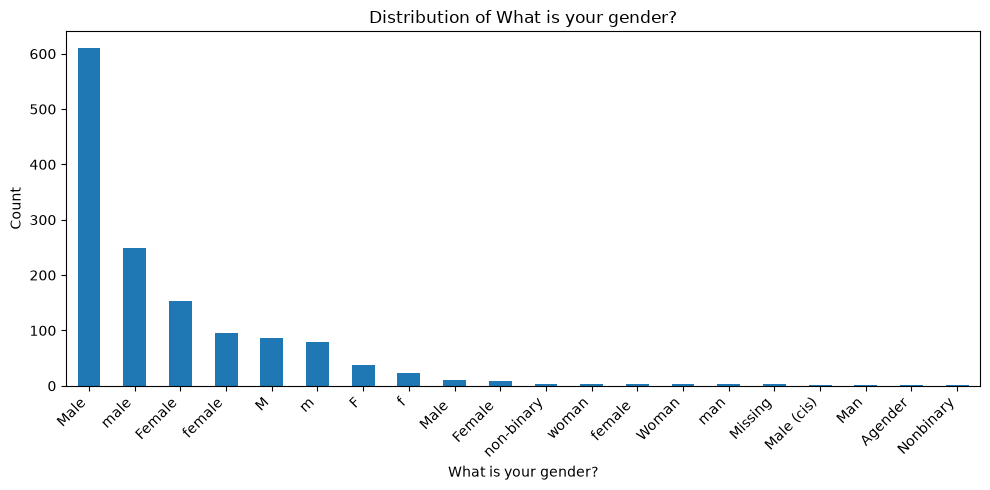

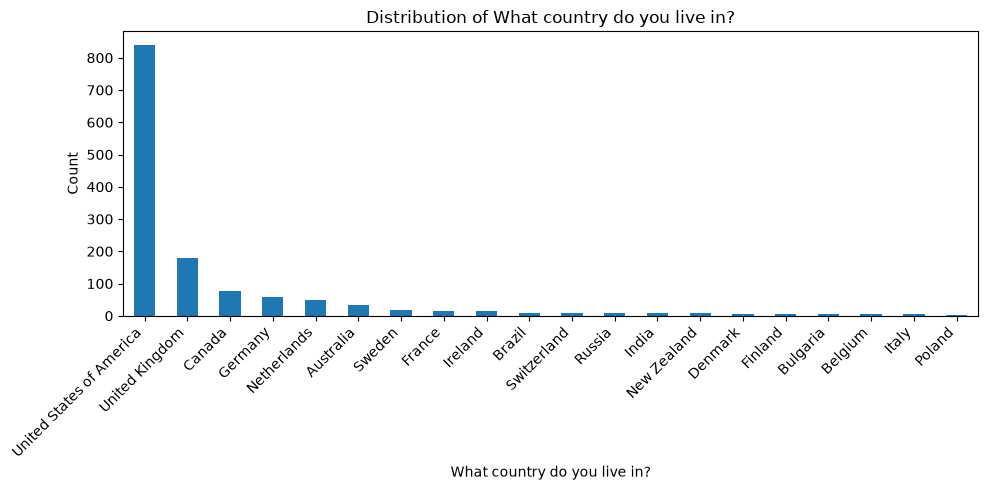

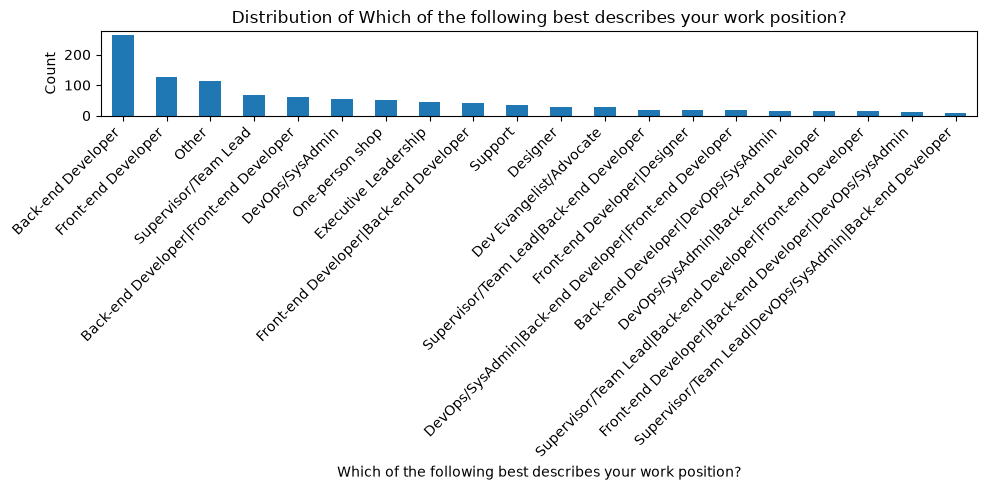

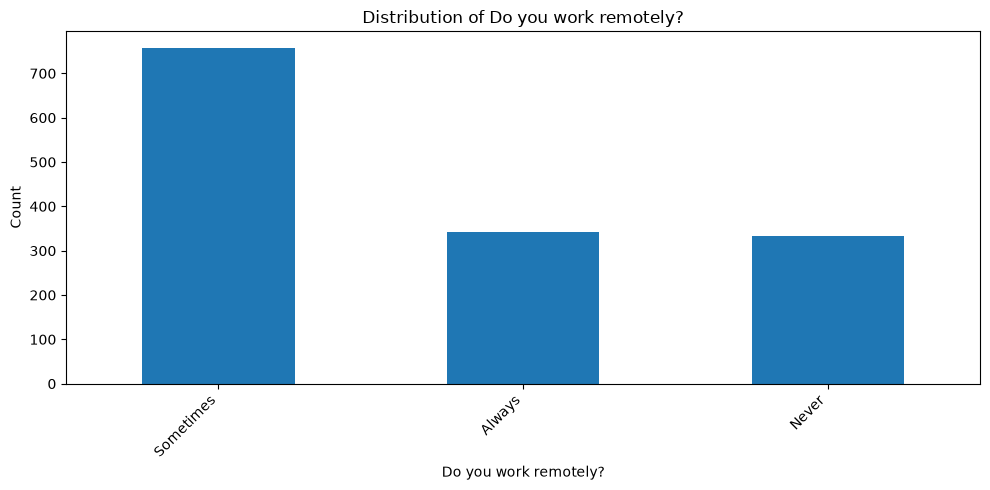

In [15]:
selected_columns = [
    "Are you self-employed?",
    "How many employees does your company or organization have?",
    "Is your employer primarily a tech company/organization?",
    "What is your age?",
    "What is your gender?",
    "What country do you live in?",
    "Which of the following best describes your work position?",
    "Do you work remotely?"
]

for column in selected_columns:
    if column not in pd.read_csv(path, nrows=0).columns:
        print(f"Column not found: {column}")
        continue

    plt.figure(figsize=(10, 5))

    values = pd.read_csv(path, usecols=[column])[column]

    if pd.api.types.is_numeric_dtype(values):
        sns.histplot(values.dropna(), kde=True)
        plt.ylabel("Count")
    else:
        values.fillna("Missing").value_counts().head(20).plot(
            kind="bar"
        )
        plt.ylabel("Count")
        plt.xticks(rotation=45, ha="right")

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.tight_layout()

    plt.savefig(
        f"{FIGURES_PATH}/{re.sub(r'.+', lambda m: {
            'Are you self-employed?': 'self_employment_distribution',
            'How many employees does your company or organization have?': 'company_size_distribution',
            'Is your employer primarily a tech company/organization?': 'tech_employer_distribution',
            'What is your age?': 'age_distribution',
            'What is your gender?': 'gender_distribution',
            'What country do you live in?': 'country_distribution',
            'Which of the following best describes your work position?': 'work_position_distribution',
            'Do you work remotely?': 'remote_work_distribution'
        }[m.group()], column)}.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

In [16]:
(
    pd.read_csv(path)
    .agg(["dtype", "nunique"])
    .T
    .rename(columns={
        "dtype": "Data Type",
        "nunique": "Unique Values"
    })
    .assign(
        Missing_Values=lambda df: pd.read_csv(path).isnull().sum(),
        Sample_Values=lambda df: [
            pd.read_csv(path)[column].dropna().unique()[:5].tolist()
            for column in df.index
        ]
    )
)

,Data Type,Unique Values,Missing_Values,Sample_Values
Are you self-employed?,int64,2,0,"[0, 1]"
How many employees does your company or organization have?,str,6,287,"[26-100, 6-25, More than 1000, 100-500, 500-1000]"
Is your employer primarily a tech company/organization?,float64,2,287,"[1.0, 0.0]"
Is your primary role within your company related to tech/IT?,float64,2,1170,"[1.0, 0.0]"
Does your employer provide mental health benefits as part of healthcare coverage?,str,4,287,"[Not eligible for coverage / N/A, No, Yes, I d..."
...,...,...,...,...
What US state or territory do you live in?,str,47,593,"[Illinois, Tennessee, Virginia, California, Ke..."
What country do you work in?,str,53,0,"[United Kingdom, United States of America, Can..."
What US state or territory do you work in?,str,48,582,"[Illinois, Tennessee, Virginia, California, Ke..."
Which of the following best describes your work position?,str,264,0,"[Back-end Developer, Back-end Developer|Front-..."


In [17]:
(
    pd.read_csv(path)
    .apply(lambda column: pd.Series({
        "Current dtype": str(column.dtype),
        "Intended storage": (
            "object/string"
            if pd.api.types.is_string_dtype(column.dtype)
            or column.dtype == object
            else "boolean"
            if pd.api.types.is_bool_dtype(column.dtype)
            else "integer"
            if pd.api.types.is_integer_dtype(column.dtype)
            else "float"
            if pd.api.types.is_float_dtype(column.dtype)
            else "category"
        ),
        "Missing values": column.isna().sum(),
        "Unique values": column.nunique(),
        "Examples": column.dropna().unique()[:5].tolist()
    }))
    .T
)

,Current dtype,Intended storage,Missing values,Unique values,Examples
Are you self-employed?,int64,integer,0,2,"[0, 1]"
How many employees does your company or organization have?,str,object/string,287,6,"[26-100, 6-25, More than 1000, 100-500, 500-1000]"
Is your employer primarily a tech company/organization?,float64,float,287,2,"[1.0, 0.0]"
Is your primary role within your company related to tech/IT?,float64,float,1170,2,"[1.0, 0.0]"
Does your employer provide mental health benefits as part of healthcare coverage?,str,object/string,287,4,"[Not eligible for coverage / N/A, No, Yes, I d..."
...,...,...,...,...,...
What US state or territory do you live in?,str,object/string,593,47,"[Illinois, Tennessee, Virginia, California, Ke..."
What country do you work in?,str,object/string,0,53,"[United Kingdom, United States of America, Can..."
What US state or territory do you work in?,str,object/string,582,48,"[Illinois, Tennessee, Virginia, California, Ke..."
Which of the following best describes your work position?,str,object/string,0,264,"[Back-end Developer, Back-end Developer|Front-..."


In [18]:
# Column classification report
(
    pd.read_csv(path)
    .apply(
        lambda column: pd.Series({
            "Classification": (
                "Free-text"
                if column.name in [
                    "Why or why not?",
                    "Why or why not?.1"
                ]
                or "why or why not" in column.name.lower()
                else "Numerical, discrete"
                if column.name == "What is your age?"
                else "Ordinal categorical"
                if column.name in [
                    "How many employees does your company or organization have?",
                    "If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",
                    "How willing would you be to share with friends and family that you have a mental illness?",
                    "If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?"
                ]
                else "Nominal categorical"
                if column.name in [
                    "What is your gender?",
                    "What country do you live in?",
                    "What US state or territory do you live in?",
                    "What country do you work in?",
                    "What US state or territory do you work in?",
                    "Which of the following best describes your work position?"
                ]
                else "Binary"
                if column.name in [
                    "Are you self-employed?",
                    "Is your employer primarily a tech company/organization?",
                    "Is your primary role within your company related to tech/IT?",
                    "Do you have previous employers?",
                    "Do you have a family history of mental illness?",
                    "Have you had a mental health disorder in the past?",
                    "Do you currently have a mental health disorder?",
                    "Have you been diagnosed with a mental health condition by a medical professional?",
                    "Have you ever sought treatment for a mental health issue from a mental health professional?",
                    "Do you work remotely?"
                ]
                else "Categorical — inspect options"
            ),
            "Survey role": (
                "Conditional follow-up"
                if any(
                    term in column.name.lower()
                    for term in [
                        "if yes",
                        "if maybe",
                        "if so",
                        "if you have",
                        "if you have revealed",
                        "if you have been diagnosed",
                        "why or why not"
                    ]
                )
                or column.name in [
                    "What US state or territory do you live in?",
                    "What US state or territory do you work in?"
                ]
                else "General question"
            ),
            "Current dtype": str(column.dtype),
            "Suggested storage": (
                "string"
                if (
                    column.name in [
                        "Why or why not?",
                        "Why or why not?.1"
                    ]
                    or "why or why not" in column.name.lower()
                )
                else "Int64"
                if column.name == "What is your age?"
                else "category"
                if column.name in [
                    "How many employees does your company or organization have?",
                    "If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",
                    "How willing would you be to share with friends and family that you have a mental illness?",
                    "If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?",
                    "What is your gender?",
                    "What country do you live in?",
                    "What US state or territory do you live in?",
                    "What country do you work in?",
                    "What US state or territory do you work in?",
                    "Which of the following best describes your work position?"
                ]
                else "category / bool after inspecting values"
            ),
            "Missing values": column.isna().sum(),
            "Unique values": column.nunique(),
            "Examples": column.dropna().unique()[:5].tolist()
        })
    )
    .T
)


,Classification,Survey role,Current dtype,Suggested storage,Missing values,Unique values,Examples
Are you self-employed?,Binary,General question,int64,category / bool after inspecting values,0,2,"[0, 1]"
How many employees does your company or organization have?,Ordinal categorical,General question,str,category,287,6,"[26-100, 6-25, More than 1000, 100-500, 500-1000]"
Is your employer primarily a tech company/organization?,Binary,General question,float64,category / bool after inspecting values,287,2,"[1.0, 0.0]"
Is your primary role within your company related to tech/IT?,Binary,General question,float64,category / bool after inspecting values,1170,2,"[1.0, 0.0]"
Does your employer provide mental health benefits as part of healthcare coverage?,Categorical — inspect options,General question,str,category / bool after inspecting values,287,4,"[Not eligible for coverage / N/A, No, Yes, I d..."
...,...,...,...,...,...,...,...
What US state or territory do you live in?,Nominal categorical,Conditional follow-up,str,category,593,47,"[Illinois, Tennessee, Virginia, California, Ke..."
What country do you work in?,Nominal categorical,General question,str,category,0,53,"[United Kingdom, United States of America, Can..."
What US state or territory do you work in?,Nominal categorical,Conditional follow-up,str,category,582,48,"[Illinois, Tennessee, Virginia, California, Ke..."
Which of the following best describes your work position?,Nominal categorical,General question,str,category,0,264,"[Back-end Developer, Back-end Developer|Front-..."


In [19]:
(
    pd.read_csv(path)
    .apply(lambda column: column.dropna().unique()[:5].tolist())
    .rename("Examples")
    .to_frame()
    .to_string()
    .__str__()
    and open(f"{TXT_FILES}/sample_data.txt", "w", encoding="utf-8").write(
        pd.read_csv(path)
        .apply(lambda column: column.dropna().unique()[:5].tolist())
        .rename("Examples")
        .to_frame()
        .to_string()
    )
)

55103

In [20]:
(
    pd.read_csv(path)
    .apply(
        lambda column: pd.Series({
            "Classification": {
                "Are you self-employed?": "Binary categorical",
                "How many employees does your company or organization have?": "Ordinal categorical",
                "Is your employer primarily a tech company/organization?": "Binary categorical",
                "Is your primary role within your company related to tech/IT?": "Binary categorical",
                "Does your employer provide mental health benefits as part of healthcare coverage?": "Nominal categorical",
                "Do you know the options for mental health care available under your employer-provided coverage?": "Ordinal categorical",
                "Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?": "Nominal categorical",
                "Does your employer offer resources to learn more about mental health concerns and options for seeking help?": "Nominal categorical",
                "Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?": "Nominal categorical",
                "If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:": "Ordinal categorical",
                "Do you think that discussing a mental health disorder with your employer would have negative consequences?": "Ordinal categorical",
                "Do you think that discussing a physical health issue with your employer would have negative consequences?": "Ordinal categorical",
                "Would you feel comfortable discussing a mental health disorder with your coworkers?": "Ordinal categorical",
                "Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?": "Ordinal categorical",
                "Do you feel that your employer takes mental health as seriously as physical health?": "Nominal categorical",
                "Have you heard of or observed negative consequences for co-workers who have been open about mental health issues in your workplace?": "Binary categorical",
                "Do you have medical coverage (private insurance or state-provided) which includes treatment of \u00a0mental health issues?": "Binary categorical",
                "Do you know local or online resources to seek help for a mental health disorder?": "Ordinal categorical",
                "If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to clients or business contacts?": "Nominal categorical",
                "If you have revealed a mental health issue to a client or business contact, do you believe this has impacted you negatively?": "Nominal categorical",
                "If you have been diagnosed or treated for a mental health disorder, do you ever reveal this to coworkers or employees?": "Nominal categorical",
                "If you have revealed a mental health issue to a coworker or employee, do you believe this has impacted you negatively?": "Nominal categorical",
                "Do you believe your productivity is ever affected by a mental health issue?": "Nominal categorical",
                "If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?": "Ordinal categorical",
                "Do you have previous employers?": "Binary categorical",
                "Have your previous employers provided mental health benefits?": "Ordinal categorical",
                "Were you aware of the options for mental health care provided by your previous employers?": "Ordinal categorical",
                "Did your previous employers ever formally discuss mental health (as part of a wellness campaign or other official communication)?": "Ordinal categorical",
                "Did your previous employers provide resources to learn more about mental health issues and how to seek help?": "Ordinal categorical",
                "Was your anonymity protected if you chose to take advantage of mental health or substance abuse treatment resources with previous employers?": "Ordinal categorical",
                "Do you think that discussing a mental health disorder with previous employers would have negative consequences?": "Ordinal categorical",
                "Do you think that discussing a physical health issue with previous employers would have negative consequences?": "Ordinal categorical",
                "Would you have been willing to discuss a mental health issue with your previous co-workers?": "Ordinal categorical",
                "Would you have been willing to discuss a mental health issue with your direct supervisor(s)?": "Ordinal categorical",
                "Did you feel that your previous employers took mental health as seriously as physical health?": "Ordinal categorical",
                "Did you hear of or observe negative consequences for co-workers with mental health issues in your previous workplaces?": "Ordinal categorical",
                "Would you be willing to bring up a physical health issue with a potential employer in an interview?": "Ordinal categorical",
                "Why or why not?": "Free-text",
                "Would you bring up a mental health issue with a potential employer in an interview?": "Ordinal categorical",
                "Why or why not?.1": "Free-text",
                "Do you feel that being identified as a person with a mental health issue would hurt your career?": "Ordinal categorical",
                "Do you think that team members/co-workers would view you more negatively if they knew you suffered from a mental health issue?": "Ordinal categorical",
                "How willing would you be to share with friends and family that you have a mental illness?": "Ordinal categorical",
                "Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?": "Nominal categorical",
                "Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?": "Ordinal categorical",
                "Do you have a family history of mental illness?": "Nominal categorical",
                "Have you had a mental health disorder in the past?": "Nominal categorical",
                "Do you currently have a mental health disorder?": "Nominal categorical",
                "If yes, what condition(s) have you been diagnosed with?": "Multi-label categorical",
                "If maybe, what condition(s) do you believe you have?": "Multi-label categorical",
                "Have you been diagnosed with a mental health condition by a medical professional?": "Binary categorical",
                "If so, what condition(s) were you diagnosed with?": "Multi-label categorical",
                "Have you ever sought treatment for a mental health issue from a mental health professional?": "Binary categorical",
                "If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?": "Ordinal categorical",
                "If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?": "Ordinal categorical",
                "What is your age?": "Numerical — discrete",
                "What is your gender?": "Nominal categorical",
                "What country do you live in?": "Nominal categorical",
                "What US state or territory do you live in?": "Nominal categorical",
                "What country do you work in?": "Nominal categorical",
                "What US state or territory do you work in?": "Nominal categorical",
                "Which of the following best describes your work position?": (
                    "Multi-label categorical"
                    if column.dropna().astype(str).str.contains(r"\|").any()
                    else "Nominal categorical"
                ),
                "Do you work remotely?": "Ordinal categorical",
            }.get(column.name, "Needs manual inspection"),

            "Survey role": (
                "Conditional response"
                if (
                    column.name.startswith("If ")
                    or column.name in ["Why or why not?", "Why or why not?.1"]
                )
                else "Standard survey question"
            ),

            "Suggested storage": (
                "Int64"
                if column.name == "What is your age?"
                else "boolean"
                if column.name in [
                    "Are you self-employed?",
                    "Is your employer primarily a tech company/organization?",
                    "Is your primary role within your company related to tech/IT?",
                    "Do you have previous employers?",
                    "Have you been diagnosed with a mental health condition by a medical professional?",
                    "Have you ever sought treatment for a mental health issue from a mental health professional?",
                ]
                else "category"
                if column.name != "Why or why not?"
                and column.name != "Why or why not?.1"
                and not (
                    pd.api.types.is_string_dtype(column.dtype)
                    and column.nunique() > 50
                    and column.name not in [
                        "What is your gender?",
                        "What country do you live in?",
                        "What US state or territory do you live in?",
                        "What country do you work in?",
                        "What US state or territory do you work in?",
                    ]
                )
                else "string"
            ),

            "Missing values": column.isna().sum(),
            "Unique values": column.nunique(),
            "Examples": column.dropna().unique()[:5].tolist(),
        })
    )
    .T
    .rename_axis("Column names")
    .reset_index()
    .to_csv(f"{TABLES_PATH}/column_classification.csv", encoding="utf-8", index=False)
    or display(pd.read_csv(f"{TABLES_PATH}/column_classification.csv"))
)

,Column names,Classification,Survey role,Suggested storage,Missing values,Unique values,Examples
0,Are you self-employed?,Binary categorical,Standard survey question,boolean,0,2,"[0, 1]"
1,How many employees does your company or organi...,Ordinal categorical,Standard survey question,category,287,6,"['26-100', '6-25', 'More than 1000', '100-500'..."
2,Is your employer primarily a tech company/orga...,Binary categorical,Standard survey question,boolean,287,2,"[1.0, 0.0]"
3,Is your primary role within your company relat...,Binary categorical,Standard survey question,boolean,1170,2,"[1.0, 0.0]"
4,Does your employer provide mental health benef...,Nominal categorical,Standard survey question,category,287,4,"['Not eligible for coverage / N/A', 'No', 'Yes..."
...,...,...,...,...,...,...,...
58,What US state or territory do you live in?,Nominal categorical,Standard survey question,category,593,47,"['Illinois', 'Tennessee', 'Virginia', 'Califor..."
59,What country do you work in?,Nominal categorical,Standard survey question,category,0,53,"['United Kingdom', 'United States of America',..."
60,What US state or territory do you work in?,Nominal categorical,Standard survey question,category,582,48,"['Illinois', 'Tennessee', 'Virginia', 'Califor..."
61,Which of the following best describes your wor...,Multi-label categorical,Standard survey question,string,0,264,"['Back-end Developer', 'Back-end Developer|Fro..."


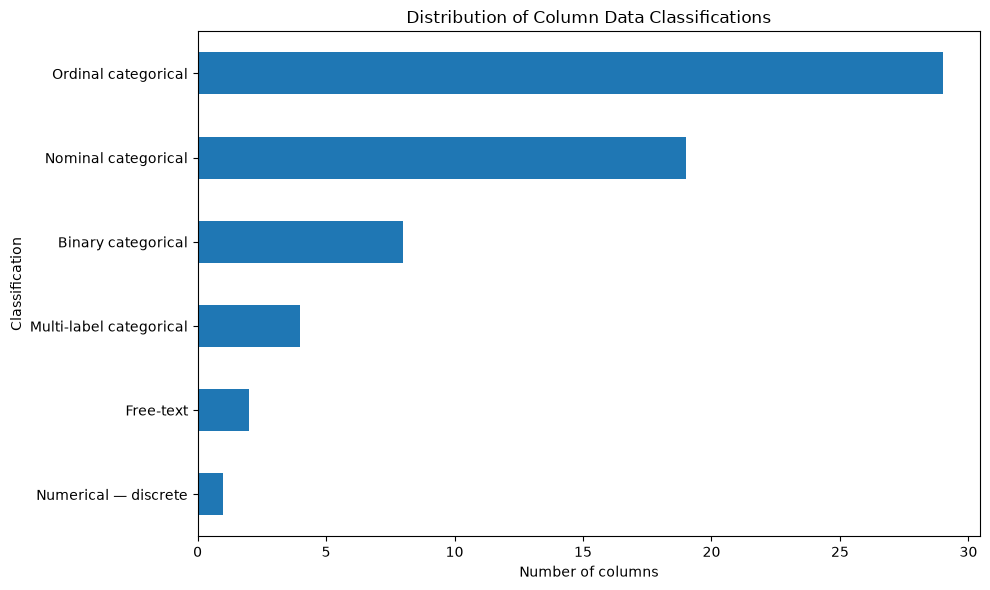

In [21]:
(
    pd.read_csv(f"{TABLES_PATH}/column_classification.csv")
    ["Classification"]
    .value_counts()
    .sort_values()
    .plot(
        kind="barh",
        figsize=(10, 6),
        title="Distribution of Column Data Classifications",
        xlabel="Number of columns",
        ylabel="Classification",
        grid=False,
    )
)

plt.tight_layout()
plt.savefig(
    f"{FIGURES_PATH}/column_data_classification.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 1.5 Inspecting the Age column

In [22]:
(pd.read_csv(path))["What is your age?"].describe()

count    1433.000000
mean       34.286113
std        11.290931
min         3.000000
25%        28.000000
50%        33.000000
75%        39.000000
max       323.000000
Name: What is your age?, dtype: float64

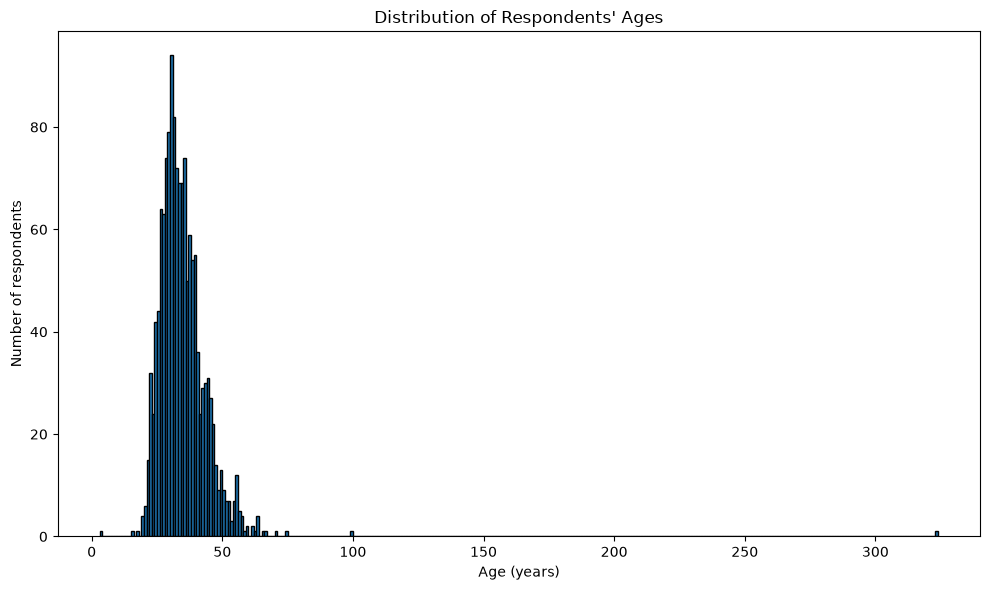

In [23]:
(
    pd.read_csv(path)["What is your age?"]
    .pipe(pd.to_numeric, errors="coerce")
    .dropna()
    .plot(
        kind="hist",
        bins=range(
            int(pd.read_csv(path)["What is your age?"].min()),
            int(pd.read_csv(path)["What is your age?"].max()) + 2
        ),
        figsize=(10, 6),
        edgecolor="black",
        title="Distribution of Respondents' Ages",
        xlabel="Age (years)",
        ylabel="Number of respondents",
    )
)

plt.tight_layout()
plt.savefig(
    f"{FIGURES_PATH}/visualising_age_range.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [24]:
(
    pd.read_csv(path)["What is your age?"]
    .pipe(pd.to_numeric, errors="coerce")
    .loc[lambda age: (age < 18) | (age > 75)]
    .value_counts()
    .sort_index()
)

What is your age?
3      1
15     1
17     1
99     1
323    1
Name: count, dtype: int64

In [25]:
(
    pd.read_csv(path)
    .assign(
        age_numeric=lambda df: pd.to_numeric(
            df["What is your age?"],
            errors="coerce"
        )
    )
    .loc[lambda df: (df["age_numeric"] < 18) | (df["age_numeric"] > 75)]
)

,Are you self-employed?,How many employees does your company or organization have?,Is your employer primarily a tech company/organization?,Is your primary role within your company related to tech/IT?,Does your employer provide mental health benefits as part of healthcare coverage?,Do you know the options for mental health care available under your employer-provided coverage?,"Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?",Does your employer offer resources to learn more about mental health concerns and options for seeking help?,Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?,"If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:",...,"If you have a mental health issue, do you feel that it interferes with your work when NOT being treated effectively?",What is your age?,What is your gender?,What country do you live in?,What US state or territory do you live in?,What country do you work in?,What US state or territory do you work in?,Which of the following best describes your work position?,Do you work remotely?,age_numeric
93,0,6-25,1.0,NaN,No,NaN,No,No,I don't know,Somewhat difficult,...,Sometimes,17,male,Brazil,NaN,Brazil,NaN,Front-end Developer,Always,17
372,0,6-25,1.0,NaN,Yes,No,No,I don't know,Yes,Somewhat easy,...,Often,99,Other,United States of America,Michigan,United States of America,Michigan,Supervisor/Team Lead,Sometimes,99
564,0,100-500,1.0,NaN,Yes,No,I don't know,I don't know,I don't know,I don't know,...,Not applicable to me,323,Male,United States of America,Oregon,United States of America,Oregon,Back-end Developer,Sometimes,323
656,0,More than 1000,1.0,NaN,Yes,I am not sure,Yes,Yes,I don't know,Somewhat easy,...,Sometimes,3,Male,Canada,NaN,Canada,NaN,Back-end Developer,Sometimes,3
808,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Not applicable to me,15,male,Canada,NaN,Canada,NaN,Other,Sometimes,15


In [26]:
(pd.read_csv(path))["What is your gender?"].describe()

count     1430
unique      70
top       Male
freq       610
Name: What is your gender?, dtype: object

#### Interpreting Gender

- 1,430 respondents provided a non-missing gender response.
- There are 70 distinct labels in the column.
- Male is the most frequent exact response.
- Male appears 610 times.

In [27]:
(
    pd.read_csv(path)["What is your gender?"]
    .value_counts(dropna=False)
)

What is your gender?
Male                                       610
male                                       249
Female                                     153
female                                      95
M                                           86
                                          ... 
female-bodied; no feelings about gender      1
cis man                                      1
AFAB                                         1
Transgender woman                            1
MALE                                         1
Name: count, Length: 71, dtype: int64

In [28]:
with pd.option_context("display.max_columns", None):
    display(pd.read_csv(path)["What is your gender?"].unique().tolist())

['Male',
 'male',
 'Male ',
 'Female',
 'M',
 'female',
 'm',
 'I identify as female.',
 'female ',
 'Bigender',
 'non-binary',
 'Female assigned at birth ',
 'F',
 'Woman',
 'man',
 'fm',
 'f',
 'Cis female ',
 'Transitioned, M2F',
 'Genderfluid (born female)',
 'Other/Transfeminine',
 'Female or Multi-Gender Femme',
 'Female ',
 'woman',
 'female/woman',
 'Cis male',
 'Male.',
 'Androgynous',
 'male 9:1 female, roughly',
 nan,
 'Male (cis)',
 'Other',
 'nb masculine',
 'Cisgender Female',
 'Man',
 'Sex is male',
 'none of your business',
 'genderqueer',
 'cis male',
 'Human',
 'Genderfluid',
 'Enby',
 'Malr',
 'genderqueer woman',
 'mtf',
 'Queer',
 'Agender',
 'Dude',
 'Fluid',
 "I'm a man why didn't you make this a drop down question. You should of asked sex? And I would of answered yes please. Seriously how much text can this take? ",
 'mail',
 'M|',
 'Male/genderqueer',
 'fem',
 'Nonbinary',
 'male ',
 'human',
 'Female (props for making this a freeform field, though)',
 ' Female

In [29]:
(
    pd.read_csv(path)["What is your gender?"]
    .dropna()
    .sort_values(key=lambda column: column.str.lower().str.strip())
)

1374           AFAB
773         Agender
1393        Agender
291     Androgynous
29         Bigender
           ...     
742           Woman
786           Woman
55            Woman
1236          woman
247           woman
Name: What is your gender?, Length: 1430, dtype: str

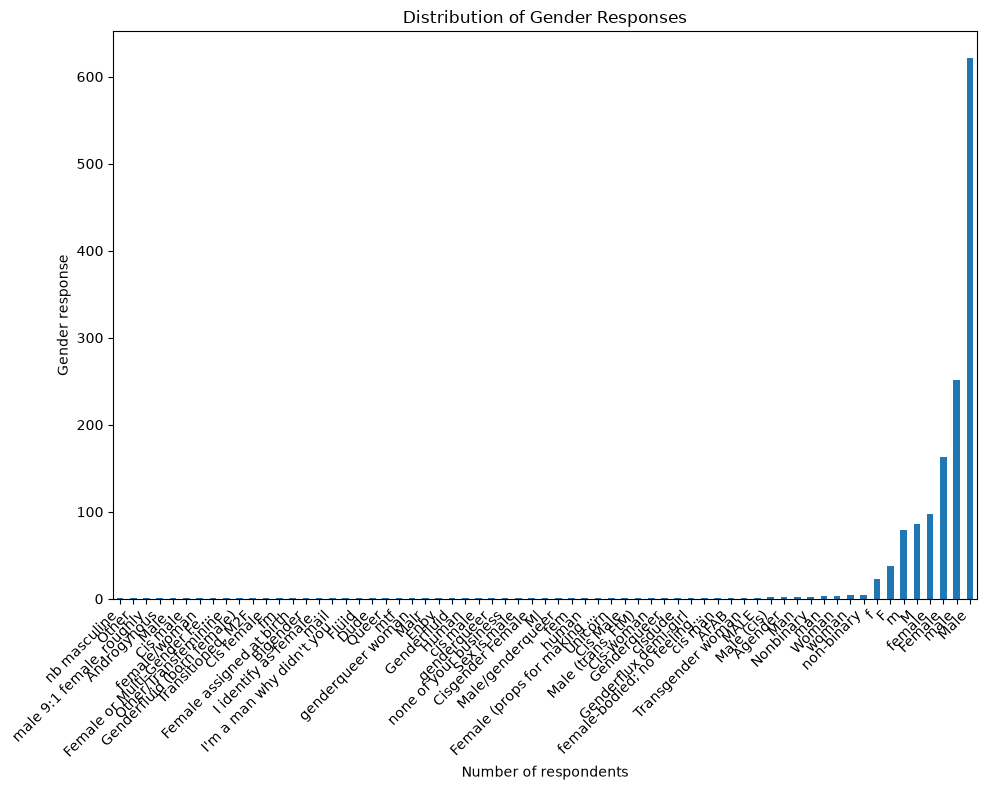

In [30]:
(
    pd.read_csv(path)["What is your gender?"]
    .dropna()
    .str.strip()
    .value_counts()
    .sort_values()
    .rename(index=lambda label: label[:25] + "..." if len(label) > 25 else label)
    .plot(
        kind="bar",
        figsize=(10, 8),
        title="Distribution of Gender Responses",
        xlabel="Number of respondents",
        ylabel="Gender response",
    )
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(
    f"{FIGURES_PATH}/distribution_of_gender_responses.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [31]:
(pd.read_csv(path))["Are you self-employed?"].describe()

count    1433.000000
mean        0.200279
std         0.400349
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         1.000000
Name: Are you self-employed?, dtype: float64

In [32]:
(
    pd.read_csv(path)["Are you self-employed?"]
    .value_counts(dropna=False)
    .sort_index()
)

Are you self-employed?
0    1146
1     287
Name: count, dtype: int64

In [33]:
(
    pd.read_csv(path)["How many employees does your company or organization have?"]
    .value_counts(dropna=False)
)

How many employees does your company or organization have?
26-100            292
NaN               287
More than 1000    256
100-500           248
6-25              210
500-1000           80
1-5                60
Name: count, dtype: int64

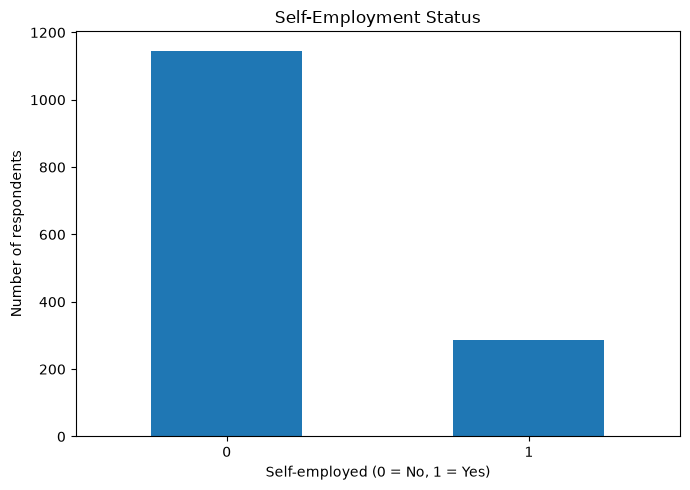

In [34]:
(
    pd.read_csv(path)["Are you self-employed?"]
    .value_counts()
    .sort_index()
    .plot(
        kind="bar",
        figsize=(7, 5),
        title="Self-Employment Status",
        xlabel="Self-employed (0 = No, 1 = Yes)",
        ylabel="Number of respondents",
        rot=0,
    )
)

plt.tight_layout()
plt.savefig(
    f"{FIGURES_PATH}/self_employment_status.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

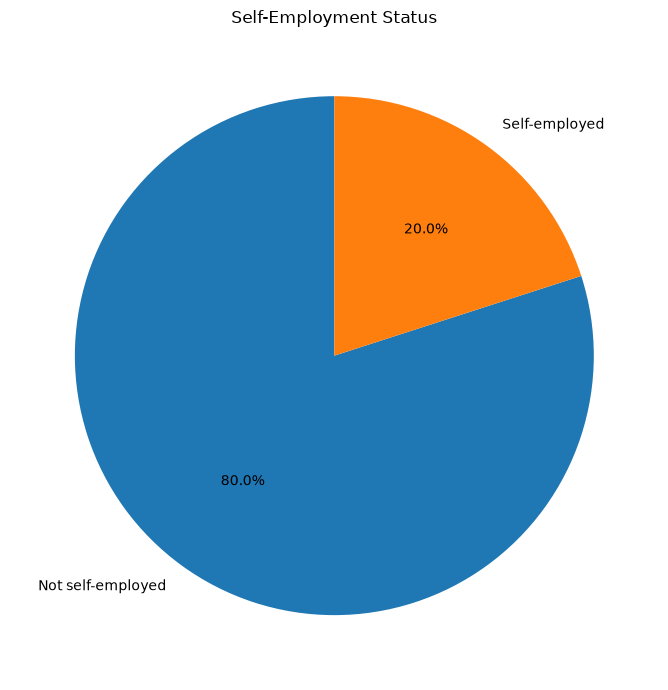

In [35]:
(
    pd.read_csv(path)["Are you self-employed?"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Not self-employed", 1: "Self-employed"})
    .plot(
        kind="pie",
        figsize=(7, 7),
        autopct="%1.1f%%",
        startangle=90,
        ylabel="",
        title="Self-Employment Status",
    )
)

plt.tight_layout()
plt.savefig(
    f"{FIGURES_PATH}/self_employment_relative_percentage.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

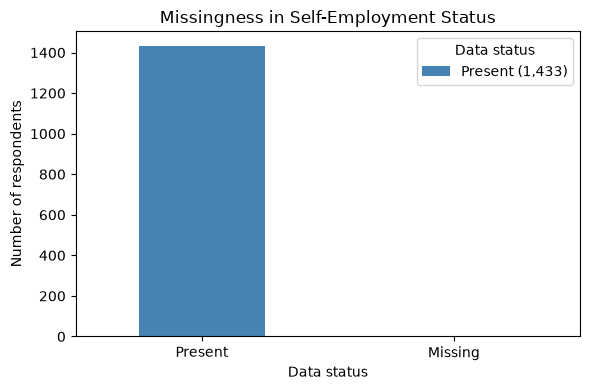

In [36]:
(
    pd.read_csv(path)["Are you self-employed?"]
    .isna()
    .value_counts()
    .reindex([False, True], fill_value=0)
    .rename(index={False: "Present", True: "Missing"})
    .plot(
        kind="bar",
        figsize=(6, 4),
        title="Missingness in Self-Employment Status",
        xlabel="Data status",
        ylabel="Number of respondents",
        rot=0,
        color=["steelblue", "darkorange"],
    )
)

plt.legend(
    [
        f"Present ({pd.read_csv(path)['Are you self-employed?'].notna().sum():,})",
        f"Missing ({pd.read_csv(path)['Are you self-employed?'].isna().sum():,})",
    ],
    title="Data status",
)

plt.tight_layout()
plt.savefig(
    f"{FIGURES_PATH}/missingness_in_self_employment.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [38]:
pd.read_csv(path)["How many employees does your company or organization have?"].value_counts(dropna=False)

How many employees does your company or organization have?
26-100            292
NaN               287
More than 1000    256
100-500           248
6-25              210
500-1000           80
1-5                60
Name: count, dtype: int64

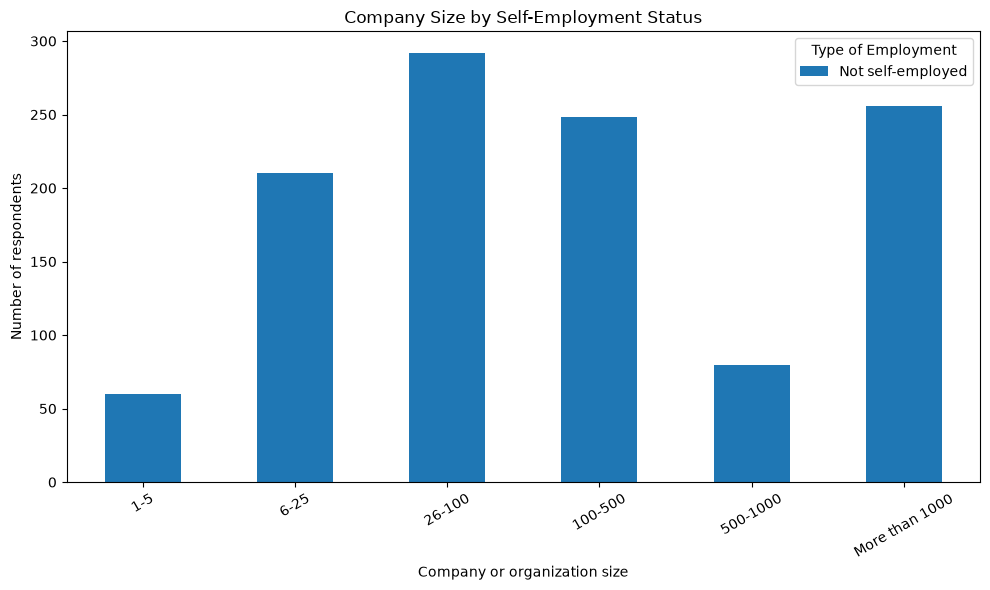

In [39]:
(
    pd.crosstab(
        pd.read_csv(path)["How many employees does your company or organization have?"],
        pd.to_numeric(
            pd.read_csv(path)["Are you self-employed?"],
            errors="coerce",
        ),
    )
    .reindex(
        ["1-5", "6-25", "26-100", "100-500", "500-1000", "More than 1000"]
    )
    .rename(columns={0: "Not self-employed", 1: "Self-employed"})
    .plot(
        kind="bar",
        figsize=(10, 6),
        title="Company Size by Self-Employment Status",
        xlabel="Company or organization size",
        ylabel="Number of respondents",
        rot=30,
    )
)

plt.legend(title="Type of Employment")
plt.tight_layout()
plt.savefig(
    f"{FIGURES_PATH}/company_size_by_self_employment.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [40]:
pd.crosstab(
    pd.to_numeric(
        pd.read_csv(path)["Are you self-employed?"],
        errors="coerce",
    ),
    pd.read_csv(path)["How many employees does your company or organization have?"],
    dropna=False,
)

How many employees does your company or organization have?,1-5,100-500,26-100,500-1000,6-25,More than 1000,NaN
Are you self-employed?,,,,,,,
0,60,248,292,80,210,256,0
1,0,0,0,0,0,0,287


In [41]:
pd.read_csv(path)[
    [
        "Are you self-employed?",
        "How many employees does your company or organization have?",
    ]
].value_counts(dropna=False).sort_index()

Are you self-employed?  How many employees does your company or organization have?
0                       1-5                                                            60
                        100-500                                                       248
                        26-100                                                        292
                        500-1000                                                       80
                        6-25                                                          210
                        More than 1000                                                256
1                       NaN                                                           287
Name: count, dtype: int64

In [42]:
# Verufy the pattern
pd.crosstab(
    pd.to_numeric(
        pd.read_csv(path)["Are you self-employed?"],
        errors="coerce",
    ),
    pd.read_csv(path)["How many employees does your company or organization have?"],
    dropna=False,
    margins=True,
)

How many employees does your company or organization have?,1-5,100-500,26-100,500-1000,6-25,More than 1000,NaN,All
Are you self-employed?,,,,,,,,
0,60,248,292,80,210,256,0,1146
1,0,0,0,0,0,0,287,287
All,60,248,292,80,210,256,287,1433


### Self-Employment Status and Company Size: Missing-Data Assessment

#### Observed Relationship

An examination of `Are you self-employed?` and `How many employees does your company or organization have?` confirmed a consistent pattern in the dataset: respondents who are not self-employed have recorded company-size categories, whereas respondents who are self-employed have missing company-size values.

The observed combinations are summarized below.

| Self-employment value | Company-size value | Interpretation |
| :--- | :--- | :--- |
| `0` | `1-5` | Not self-employed; company size recorded |
| `0` | `6-25` | Not self-employed; company size recorded |
| `0` | `26-100` | Not self-employed; company size recorded |
| `0` | `100-500` | Not self-employed; company size recorded |
| `0` | `500-1000` | Not self-employed; company size recorded |
| `0` | `More than 1000` | Not self-employed; company size recorded |
| `1` | `NaN` | Self-employed; company size missing |

Here, `0` represents respondents who are not self-employed, while `1` represents self-employed respondents. `NaN` indicates a missing company-size value.

#### Interpretation

The verified pattern indicates that missingness in the company-size column is systematically associated with self-employment status. Specifically, company-size values are missing for self-employed respondents, while non-self-employed respondents have recorded values across the observed company-size categories.

This suggests that the missing values may represent **structural missingness**: the company-size question may not have been applicable to self-employed respondents in the context of the survey. However, the observed pattern alone does not establish the reason for the missing values. The original survey wording and questionnaire logic should be consulted before definitively classifying these values as structurally missing.

#### Implications for Data Preparation

This relationship must be considered before selecting features and applying missing-data treatments for subsequent analyses.

- **Avoid automatic imputation:** Do not replace the missing company-size values with a typical company-size category or another arbitrary value without justification. Doing so could introduce misleading information.
- **Preserve the distinction between missingness and category membership:** A missing company-size value is not equivalent to any of the recorded company-size categories.
- **Investigate structural missingness:** Verify whether the survey design explains why company size is missing for self-employed respondents. If confirmed, document the missing values as structurally not applicable rather than treating them as ordinary unanswered questions.
- **Consider the relationship during feature selection:** Company size and self-employment status are related. Their suitability for clustering should be assessed in light of this relationship to avoid allowing missingness or redundant information to distort the resulting clusters.

The analysis confirms a systematic association between self-employment status and missing company-size values. This finding should be documented and addressed explicitly during data preparation. The missing values should remain unaltered until their meaning has been established from the survey documentation and an appropriate treatment has been justified.

In [43]:
pd.read_csv(path)[
    [
        "What country do you live in?",
        "What US state or territory do you live in?",
    ]
].info()

<class 'pandas.DataFrame'>
RangeIndex: 1433 entries, 0 to 1432
Data columns (total 2 columns):
 #   Column                                      Non-Null Count  Dtype
---  ------                                      --------------  -----
 0   What country do you live in?                1433 non-null   str  
 1   What US state or territory do you live in?  840 non-null    str  
dtypes: str(2)
memory usage: 22.5 KB


In [44]:
(
    pd.read_csv(path)[
        [
            "What country do you live in?",
            "What US state or territory do you live in?",
        ]
    ]
    .isna()
    .sum()
    .to_frame("Missing responses")
    .assign(
        Missing_percentage=lambda df: (
            df["Missing responses"]
            / len(pd.read_csv(path))
            * 100
        ).round(2)
    )
)

,Missing responses,Missing_percentage
What country do you live in?,0,0.00
What US state or territory do you live in?,593,41.38


In [45]:
pd.read_csv(path)["What country do you live in?"].value_counts()

What country do you live in?
United States of America    840
United Kingdom              180
Canada                       78
Germany                      58
Netherlands                  48
Australia                    35
Sweden                       19
France                       16
Ireland                      15
Brazil                       10
Switzerland                  10
Russia                        9
India                         9
New Zealand                   9
Denmark                       7
Finland                       7
Bulgaria                      7
Belgium                       5
Italy                         5
Poland                        4
Spain                         4
South Africa                  4
Austria                       4
Romania                       4
Czech Republic                3
Norway                        3
Pakistan                      3
Chile                         3
Lithuania                     2
Mexico                        2
Colombia   

In [46]:
pd.read_csv(path)[
    "What US state or territory do you live in?"
].value_counts(dropna=False)

What US state or territory do you live in?
NaN                     593
California              130
Illinois                 56
Michigan                 48
New York                 45
Washington               43
Texas                    43
Minnesota                42
Oregon                   37
Pennsylvania             33
Colorado                 28
Tennessee                27
Indiana                  25
Ohio                     25
Massachusetts            23
Florida                  21
North Carolina           21
Maryland                 16
Virginia                 15
Georgia                  14
Kansas                   14
Wisconsin                13
Oklahoma                 13
Nebraska                 12
Missouri                 12
New Jersey                7
Utah                      6
Vermont                   5
Connecticut               5
Iowa                      5
Maine                     5
Arizona                   5
New Hampshire             5
Kentucky                  4
North

In [47]:
pd.read_csv(path)[
    "What US state or territory do you live in?"
].unique()

<StringArray>
[                   nan,             'Illinois',            'Tennessee',
             'Virginia',           'California',             'Kentucky',
               'Oregon',         'Pennsylvania',           'New Jersey',
              'Georgia',           'Washington',             'New York',
              'Indiana',            'Minnesota',        'West Virginia',
              'Florida',        'Massachusetts',         'North Dakota',
                'Texas',             'Maryland',            'Wisconsin',
             'Michigan',              'Vermont',       'North Carolina',
               'Kansas', 'District of Columbia',               'Nevada',
                 'Utah',          'Connecticut',             'Colorado',
                 'Ohio',                 'Iowa',         'South Dakota',
             'Nebraska',                'Maine',             'Missouri',
              'Arizona',             'Oklahoma',                'Idaho',
         'Rhode Island',             

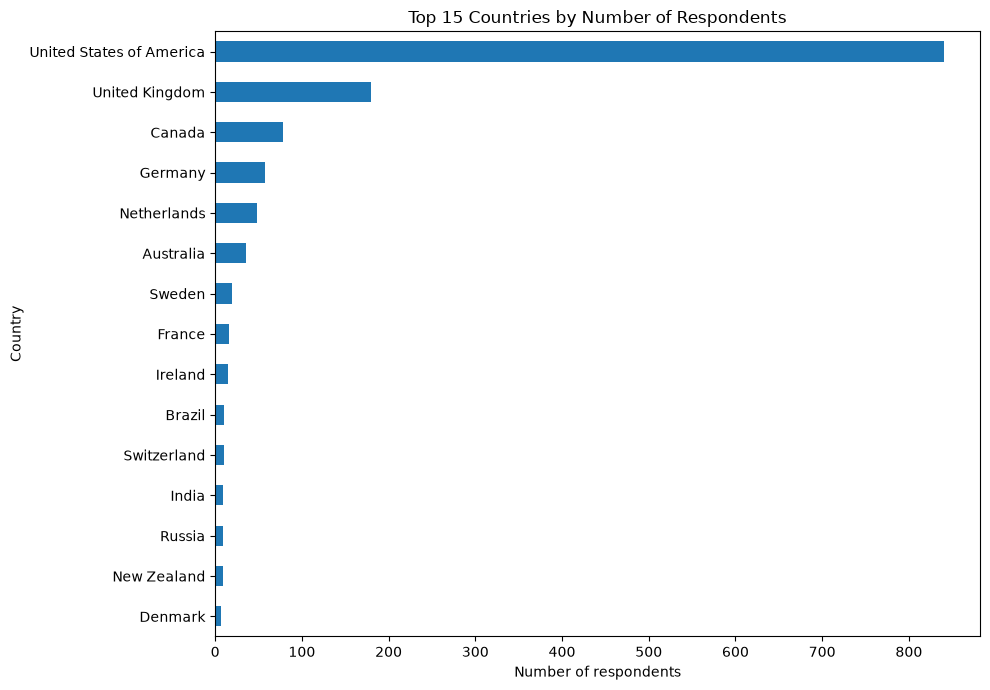

In [48]:
(
    pd.read_csv(path)["What country do you live in?"]
    .value_counts()
    .head(15)
    .sort_values()
    .plot(
        kind="barh",
        figsize=(10, 7),
        title="Top 15 Countries by Number of Respondents",
        xlabel="Number of respondents",
        ylabel="Country",
    )
)

plt.tight_layout()
plt.savefig(
    f"{FIGURES_PATH}/top_15_countries_by_respondents.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

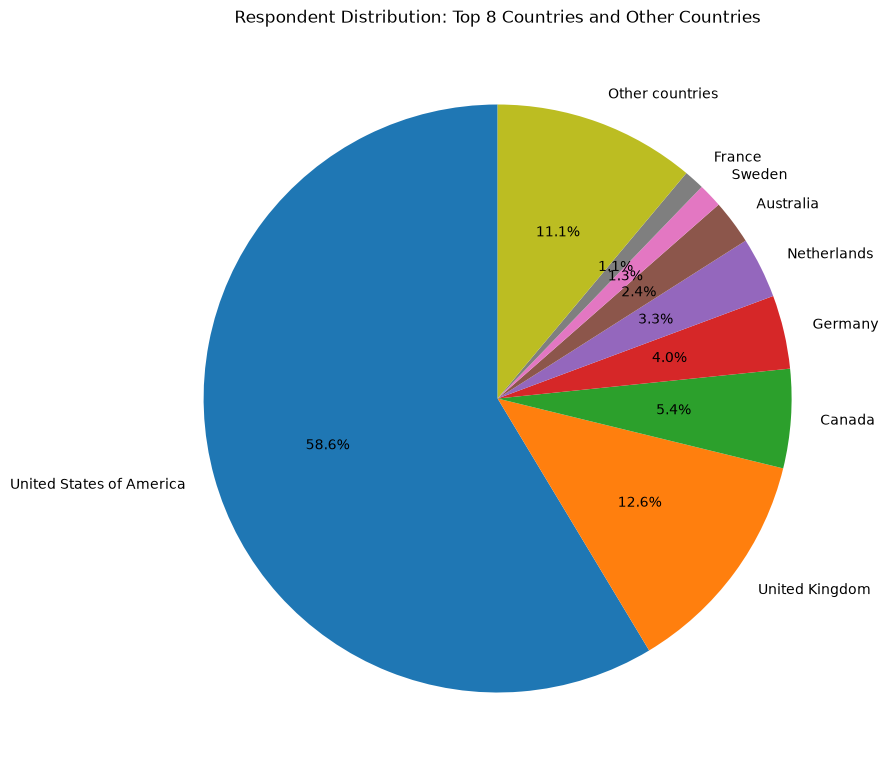

In [49]:
(
    pd.concat(
        [
            pd.read_csv(path)["What country do you live in?"]
            .value_counts()
            .head(8),
            pd.Series(
                {
                    "Other countries": pd.read_csv(path)[
                        "What country do you live in?"
                    ].value_counts().iloc[8:].sum()
                }
            ),
        ]
    )
    .plot(
        kind="pie",
        figsize=(9, 9),
        autopct="%1.1f%%",
        startangle=90,
        ylabel="",
        title="Respondent Distribution: Top 8 Countries and Other Countries",
    )
)

plt.tight_layout()
plt.savefig(
    f"{FIGURES_PATH}/respondent_distribution_for_top_8_countries.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [50]:
pd.crosstab(
    pd.read_csv(path)["What country do you live in?"].fillna(
        "Missing country"
    ),
    pd.read_csv(path)["What US state or territory do you live in?"].fillna(
        "Missing state"
    ),
)

What US state or territory do you live in?,Alabama,Alaska,Arizona,California,Colorado,Connecticut,Delaware,District of Columbia,Florida,Georgia,...,South Carolina,South Dakota,Tennessee,Texas,Utah,Vermont,Virginia,Washington,West Virginia,Wisconsin
What country do you live in?,,,,,,,,,,,,,,,,,,,,,
Afghanistan,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Algeria,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Argentina,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Australia,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Austria,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Bangladesh,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Belgium,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Bosnia and Herzegovina,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Brazil,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [51]:
(
    pd.read_csv(path)[
        [
            "What country do you live in?",
            "What US state or territory do you live in?",
        ]
    ]
    .fillna("Missing")
    .value_counts()
    .head(25)
    .rename("Respondents")
)

What country do you live in?  What US state or territory do you live in?
United Kingdom                Missing                                       180
United States of America      California                                    130
Canada                        Missing                                        78
Germany                       Missing                                        58
United States of America      Illinois                                       56
Netherlands                   Missing                                        48
United States of America      Michigan                                       48
                              New York                                       45
                              Washington                                     43
                              Texas                                          43
                              Minnesota                                      42
                              Oregon           

In [52]:
px.choropleth(
    (
        pd.read_csv(path)["What country do you live in?"]
        .replace({"United States of America": "United States"})
        .dropna()
        .value_counts()
        .rename_axis("Country")
        .reset_index(name="Respondents")
    ),
    locations="Country",
    locationmode="country names",
    color="Respondents",
    hover_name="Country",
    hover_data={"Respondents": True},
    color_continuous_scale="Viridis",
    title="Global Distribution of OSMI Survey Respondents",
).update_layout(
    title=dict(
        font=dict(size=20),
        pad=dict(t=20, b=20),
    ),
    margin=dict(l=30, r=30, t=100, b=40),
    coloraxis_colorbar=dict(
        title="Respondents",
        tickfont=dict(size=12),
        title_font=dict(size=13),
    ),
).show()

In [54]:
px.choropleth(
    (
        pd.read_csv(path)
        .loc[
            lambda df: df["What country do you live in?"].replace(
                {"United States of America": "United States"}
            ).eq("United States"),
            "What US state or territory do you live in?",
        ]
        .dropna()
        .value_counts()
        .rename_axis("State")
        .reset_index(name="Respondents")
        .assign(
            State=lambda df: df["State"].replace(
                {
                    "Alabama": "AL",
                    "Alaska": "AK",
                    "Arizona": "AZ",
                    "California": "CA",
                    "Colorado": "CO",
                    "Connecticut": "CT",
                    "Delaware": "DE",
                    "District of Columbia": "DC",
                    "Florida": "FL",
                    "Georgia": "GA",
                    "Idaho": "ID",
                    "Illinois": "IL",
                    "Indiana": "IN",
                    "Iowa": "IA",
                    "Kansas": "KS",
                    "Kentucky": "KY",
                    "Louisiana": "LA",
                    "Maine": "ME",
                    "Maryland": "MD",
                    "Massachusetts": "MA",
                    "Michigan": "MI",
                    "Minnesota": "MN",
                    "Missouri": "MO",
                    "Montana": "MT",
                    "Nebraska": "NE",
                    "Nevada": "NV",
                    "New Hampshire": "NH",
                    "New Jersey": "NJ",
                    "New Mexico": "NM",
                    "New York": "NY",
                    "North Carolina": "NC",
                    "North Dakota": "ND",
                    "Ohio": "OH",
                    "Oklahoma": "OK",
                    "Oregon": "OR",
                    "Pennsylvania": "PA",
                    "Rhode Island": "RI",
                    "South Carolina": "SC",
                    "South Dakota": "SD",
                    "Tennessee": "TN",
                    "Texas": "TX",
                    "Utah": "UT",
                    "Vermont": "VT",
                    "Virginia": "VA",
                    "Washington": "WA",
                    "West Virginia": "WV",
                    "Wisconsin": "WI",
                }
            )
        )
    ),
    locations="State",
    locationmode="USA-states",
    color="Respondents",
    hover_name="State",
    hover_data={"Respondents": True},
    scope="usa",
    color_continuous_scale="Viridis",
    title="Distribution of OSMI Survey Respondents Across US States",
).update_layout(
    title=dict(
        font=dict(size=20),
        pad=dict(t=20, b=20),
    ),
    margin=dict(l=30, r=30, t=100, b=40),
    coloraxis_colorbar=dict(
        title="Respondents",
        tickfont=dict(size=12),
        title_font=dict(size=13),
    ),
).show()

In [60]:
(
    pd.read_csv(path)[
        [
            "What country do you work in?",
            "Are you self-employed?",
        ]
    ].info()
)

<class 'pandas.DataFrame'>
RangeIndex: 1433 entries, 0 to 1432
Data columns (total 2 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   What country do you work in?  1433 non-null   str  
 1   Are you self-employed?        1433 non-null   int64
dtypes: int64(1), str(1)
memory usage: 22.5 KB


In [61]:
(
    pd.read_csv(path)[
        [
            "What country do you work in?",
            "Are you self-employed?",
        ]
    ].nunique(dropna=False)
)

What country do you work in?    53
Are you self-employed?           2
dtype: int64

In [62]:
(
    pd.read_csv(path)[
        "What country do you work in?"
    ].value_counts(dropna=False)
)

What country do you work in?
United States of America    851
United Kingdom              183
Canada                       74
Germany                      58
Netherlands                  47
Australia                    34
Sweden                       20
Ireland                      15
France                       14
Brazil                       10
Switzerland                  10
Russia                        9
India                         9
New Zealand                   9
Denmark                       7
Finland                       7
Bulgaria                      7
Belgium                       5
Poland                        4
South Africa                  4
Austria                       4
Czech Republic                3
Spain                         3
Norway                        3
Italy                         3
Romania                       3
Chile                         3
Mexico                        2
Colombia                      2
Pakistan                      2
Afghanistan

In [63]:
(
    pd.read_csv(path)[
        "Are you self-employed?"
    ].value_counts(dropna=False)
)

Are you self-employed?
0    1146
1     287
Name: count, dtype: int64

In [ ]:
(
    pd.read_csv(path)[
        [
            "What country do you work in?",
            "Are you self-employed?",
        ]
    ].isna().sum().to_frame("Missing responses").assign(
        Missing_percentage=lambda df: (
            df["Missing responses"] / len(pd.read_csv(path)) * 100
        ).round(2)
    )
)

,Missing responses,Missing_percentage
What country do you work in?,0,0.0
Are you self-employed?,0,0.0


In [70]:
pd.crosstab(
    pd.read_csv(path)["What country do you work in?"].fillna("Missing"),
    pd.read_csv(path)["Are you self-employed?"].fillna("Missing"),
    margins=True,
)

Are you self-employed?,0,1,All
What country do you work in?,,,
Afghanistan,1,1,2
Argentina,1,0,1
Australia,26,8,34
Austria,1,3,4
Bangladesh,1,0,1
Belgium,3,2,5
Bosnia and Herzegovina,2,0,2
Brazil,9,1,10
Brunei,0,1,1


In [71]:
pd.crosstab(
    pd.read_csv(path)["What country do you work in?"].fillna("Missing"),
    pd.read_csv(path)["Are you self-employed?"].fillna("Missing"),
    normalize="index",
).mul(100).round(2)

Are you self-employed?,0,1
What country do you work in?,,
Afghanistan,50.00,50.00
Argentina,100.00,0.00
Australia,76.47,23.53
Austria,25.00,75.00
Bangladesh,100.00,0.00
Belgium,60.00,40.00
Bosnia and Herzegovina,100.00,0.00
Brazil,90.00,10.00
Brunei,0.00,100.00


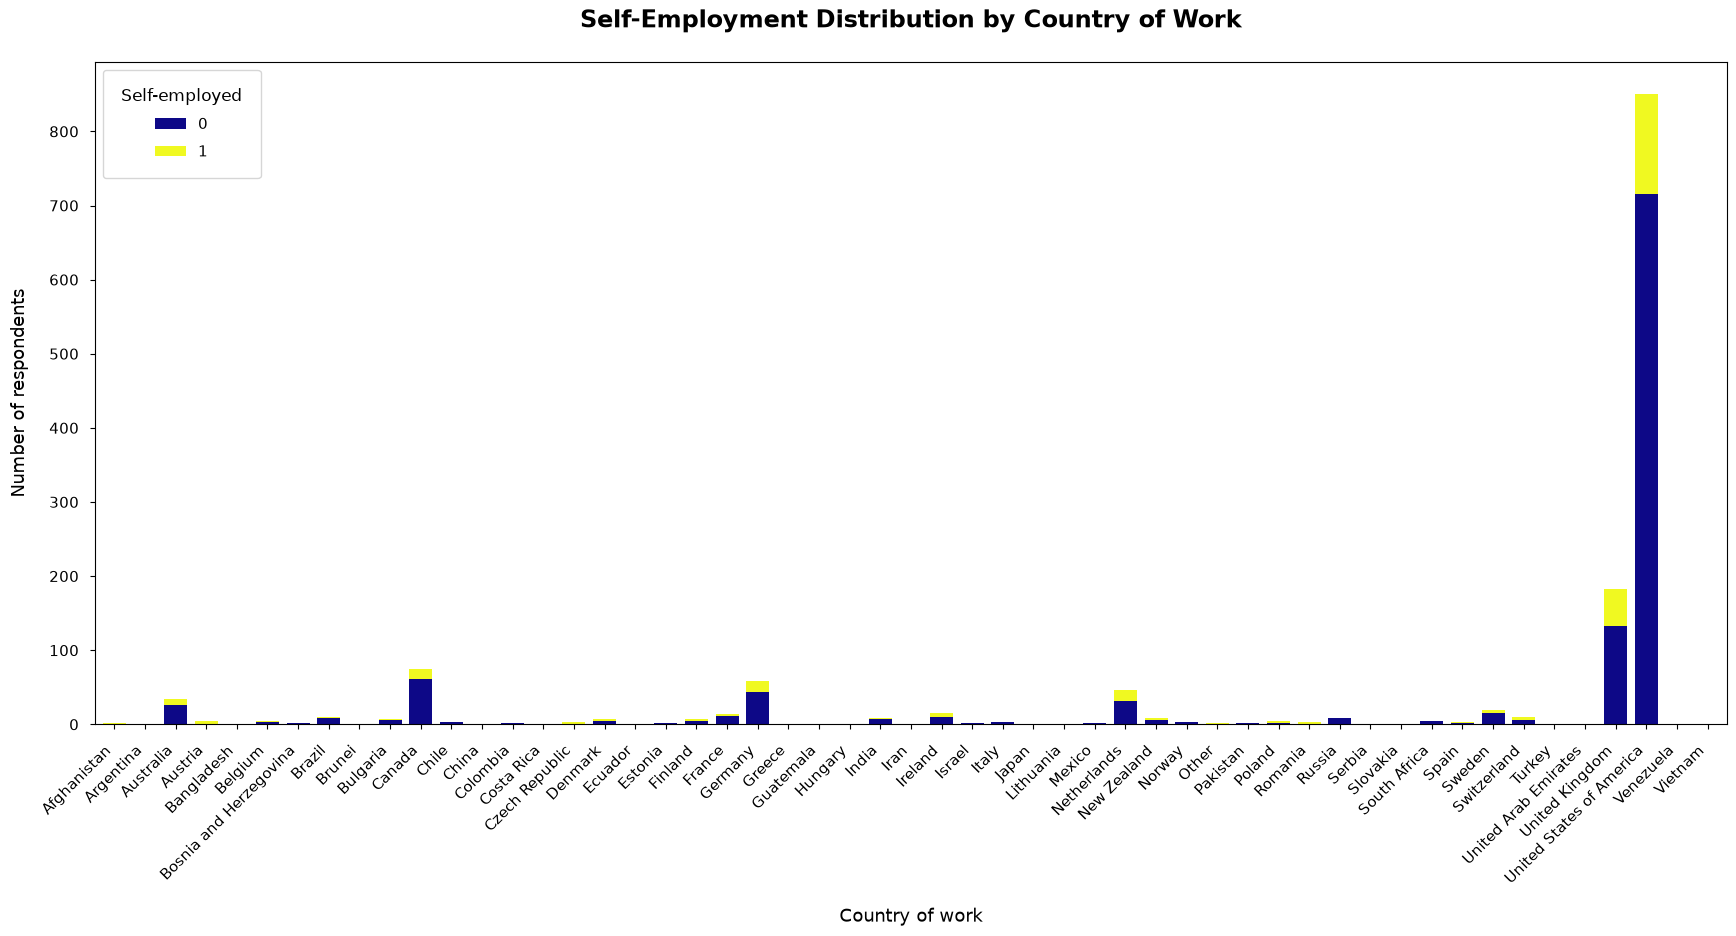

In [81]:
pd.crosstab(
    pd.read_csv(path)["What country do you work in?"],
    pd.read_csv(path)["Are you self-employed?"],
).plot(
    kind="bar",
    stacked=True,
    figsize=(18, 10),
    colormap="plasma",
    width=0.75,
    title="Self-Employment Distribution by Country of Work",
    xlabel="Country of work",
    ylabel="Number of respondents",
)

plt.title(
    "Self-Employment Distribution by Country of Work",
    fontsize=17,
    fontweight="bold",
    pad=25,
)

plt.xlabel("Country of work", fontsize=13, labelpad=15)
plt.ylabel("Number of respondents", fontsize=13, labelpad=15)

plt.xticks(rotation=45, ha="right", fontsize=11)
plt.yticks(fontsize=11)

plt.legend(
    title="Self-employed",
    fontsize=11,
    title_fontsize=12,
    frameon=True,
    borderpad=1.2,
    labelspacing=0.8,
)

plt.tick_params(axis="x", pad=10)
plt.tick_params(axis="y", pad=8)

plt.tight_layout(pad=3)
plt.savefig(
    f"{FIGURES_PATH}/employment_distribution_by_country_of_work.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [77]:
pd.crosstab(
    pd.read_csv(path)["Are you self-employed?"],
    pd.read_csv(path)["What country do you work in?"].isna(),
    normalize="index",
).mul(100).round(2)

What country do you work in?,False
Are you self-employed?,
0,100.0
1,100.0


In [82]:
px.choropleth(
    (
        pd.read_csv(path)["What country do you work in?"]
        .dropna()
        .value_counts()
        .rename_axis("Country")
        .reset_index(name="Respondents")
    ),
    locations="Country",
    locationmode="country names",
    color="Respondents",
    hover_name="Country",
    hover_data={"Respondents": True},
    color_continuous_scale="Viridis",
    title="Global Distribution of OSMI Survey Respondents by Country of Work",
).update_layout(
    title=dict(
        font=dict(size=20),
        pad=dict(t=20, b=20),
    ),
    margin=dict(l=30, r=30, t=100, b=40),
    coloraxis_colorbar=dict(
        title="Respondents",
        tickfont=dict(size=12),
        title_font=dict(size=13),
    ),
).show()

In [88]:
pd.read_csv(path)[
    "Have you ever sought treatment for a mental health issue from a mental health professional?"
].info()

<class 'pandas.Series'>
RangeIndex: 1433 entries, 0 to 1432
Series name: Have you ever sought treatment for a mental health issue from a mental health professional?
Non-Null Count  Dtype
--------------  -----
1433 non-null   int64
dtypes: int64(1)
memory usage: 11.3 KB


In [89]:
pd.read_csv(path)[
    "Have you ever sought treatment for a mental health issue from a mental health professional?"
].isna().sum()

np.int64(0)

In [94]:
pd.read_csv(path)[
    "Have you ever sought treatment for a mental health issue from a mental health professional?"
].value_counts(normalize=True, dropna=False).mul(100).round(2)

Have you ever sought treatment for a mental health issue from a mental health professional?
1    58.55
0    41.45
Name: proportion, dtype: float64

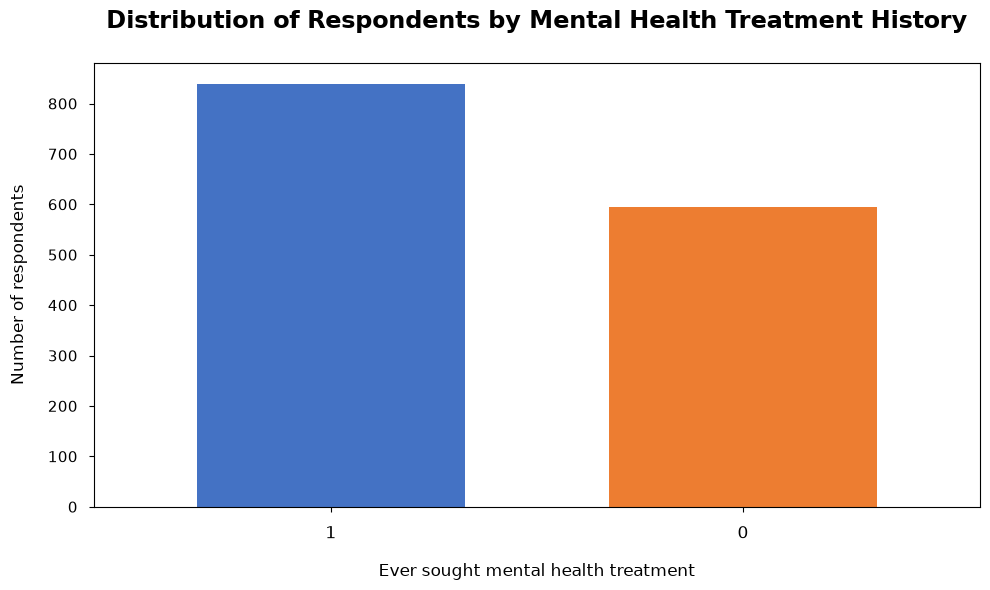

In [99]:
pd.read_csv(path)[
    "Have you ever sought treatment for a mental health issue from a mental health professional?"
].value_counts().plot(
    kind="bar",
    figsize=(10, 6),
    color=["#4472C4", "#ED7D31"],
    width=0.65,
    title="Distribution of Respondents by Mental Health Treatment History",
    xlabel="Ever sought mental health treatment",
    ylabel="Number of respondents",
)

plt.title(
    "Distribution of Respondents by Mental Health Treatment History",
    fontsize=17,
    fontweight="bold",
    pad=25,
)
plt.xlabel("Ever sought mental health treatment", fontsize=12, labelpad=15)
plt.ylabel("Number of respondents", fontsize=12, labelpad=15)
plt.xticks(rotation=0, fontsize=12)
plt.yticks(fontsize=11)
plt.tick_params(axis="x", pad=10)
plt.tick_params(axis="y", pad=8)
plt.tight_layout()
plt.savefig(
    f"{FIGURES_PATH}/dist_of_respondent_by_treatment_history.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [100]:
pd.read_csv(path)["Do you have a family history of mental illness?"].info()

<class 'pandas.Series'>
RangeIndex: 1433 entries, 0 to 1432
Series name: Do you have a family history of mental illness?
Non-Null Count  Dtype
--------------  -----
1433 non-null   str  
dtypes: str(1)
memory usage: 11.3 KB


In [101]:
pd.read_csv(path)["Do you have a family history of mental illness?"].value_counts(dropna=False)

Do you have a family history of mental illness?
Yes             670
No              488
I don't know    275
Name: count, dtype: int64

In [102]:
pd.read_csv(path)["Do you have a family history of mental illness?"].isna().sum()

np.int64(0)

In [106]:
pd.read_csv(path)[
    "Do you have a family history of mental illness?"
].value_counts(normalize=True, dropna=False).mul(100).round(2)

Do you have a family history of mental illness?
Yes             46.76
No              34.05
I don't know    19.19
Name: proportion, dtype: float64

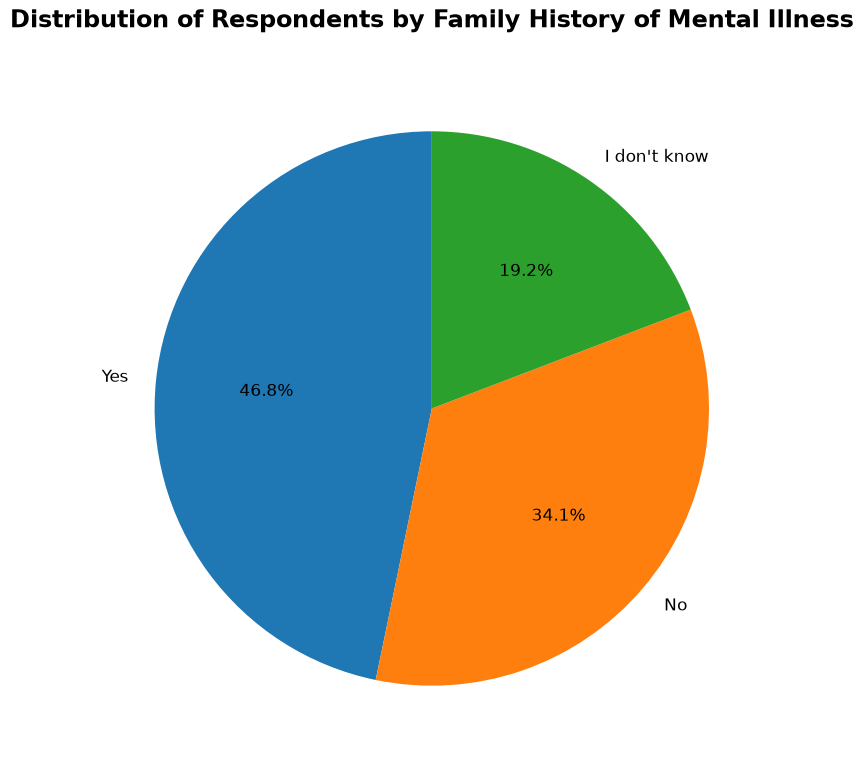

In [122]:
pd.read_csv(path)["Do you have a family history of mental illness?"].value_counts().plot(
    kind="pie",
        figsize=(9, 9),
        autopct="%1.1f%%",
        startangle=90,
        ylabel="",
        title="Distribution of Respondents by Family History of Mental Illness",
        textprops={"fontsize": 12},
)

plt.title(
    "Distribution of Respondents by Family History of Mental Illness",
    fontsize=17,
    fontweight="bold",
    pad=25,
)
plt.savefig(
    f"{FIGURES_PATH}/dist_of_respondent_by_family_history_of_mental_illness.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [109]:
pd.read_csv(path)["Have you had a mental health disorder in the past?"].info()

<class 'pandas.Series'>
RangeIndex: 1433 entries, 0 to 1432
Series name: Have you had a mental health disorder in the past?
Non-Null Count  Dtype
--------------  -----
1433 non-null   str  
dtypes: str(1)
memory usage: 11.3 KB


In [110]:
pd.read_csv(path)["Have you had a mental health disorder in the past?"].value_counts(dropna=False)

Have you had a mental health disorder in the past?
Yes      736
No       451
Maybe    246
Name: count, dtype: int64

In [113]:
pd.read_csv(path)["Have you had a mental health disorder in the past?"].isna().sum()

np.int64(0)

In [114]:
pd.read_csv(path)[
    "Have you had a mental health disorder in the past?"
].value_counts(normalize=True, dropna=False).mul(100).round(2)

Have you had a mental health disorder in the past?
Yes      51.36
No       31.47
Maybe    17.17
Name: proportion, dtype: float64

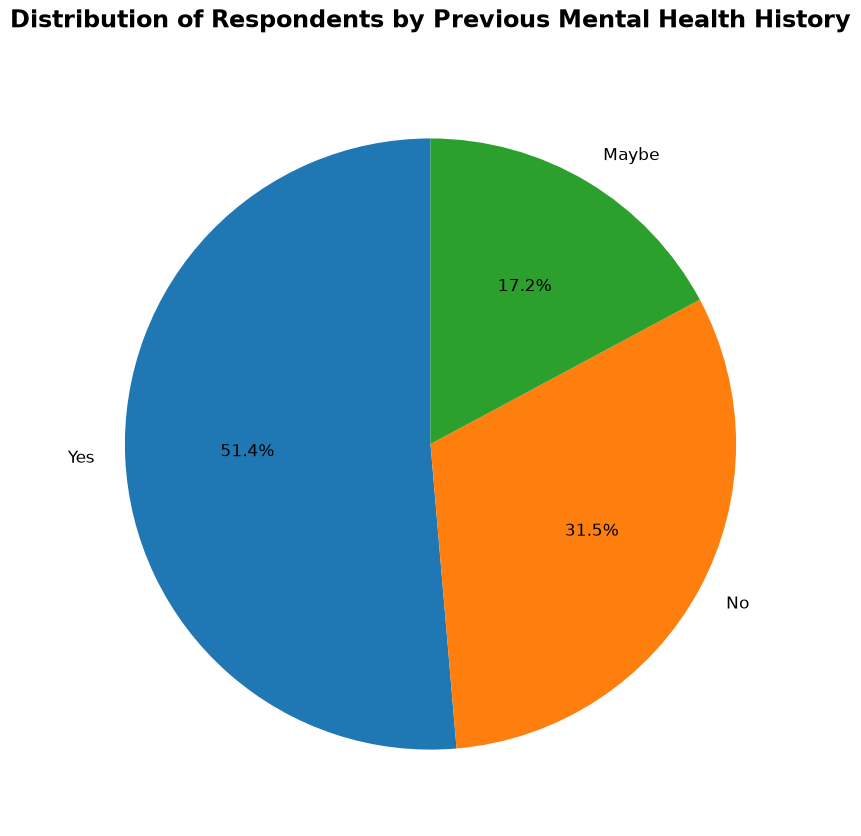

In [116]:
pd.read_csv(path)["Have you had a mental health disorder in the past?"].value_counts().plot(
    kind="pie",
    figsize=(9, 9),
    autopct="%1.1f%%",
    startangle=90,
    ylabel="",
    title="Distribution of Respondents by Previous Mental Health History",
    textprops={"fontsize": 12},
)

plt.title(
    "Distribution of Respondents by Previous Mental Health History",
    fontsize=17,
    fontweight="bold",
    pad=25,
)
plt.tight_layout(pad=3)
plt.savefig(
    f"{FIGURES_PATH}/dist_of_respondents_by_previous_mental_illness_history",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [117]:
pd.read_csv(path)["Do you currently have a mental health disorder?"].info()

<class 'pandas.Series'>
RangeIndex: 1433 entries, 0 to 1432
Series name: Do you currently have a mental health disorder?
Non-Null Count  Dtype
--------------  -----
1433 non-null   str  
dtypes: str(1)
memory usage: 11.3 KB


In [118]:
pd.read_csv(path)["Do you currently have a mental health disorder?"].value_counts(dropna=False)

Do you currently have a mental health disorder?
Yes      575
No       531
Maybe    327
Name: count, dtype: int64

In [119]:
pd.read_csv(path)["Do you currently have a mental health disorder?"].isna().sum()

np.int64(0)

In [120]:
pd.read_csv(path)[
    "Do you currently have a mental health disorder?"
].value_counts(normalize=True, dropna=False).mul(100).round(2)

Do you currently have a mental health disorder?
Yes      40.13
No       37.06
Maybe    22.82
Name: proportion, dtype: float64

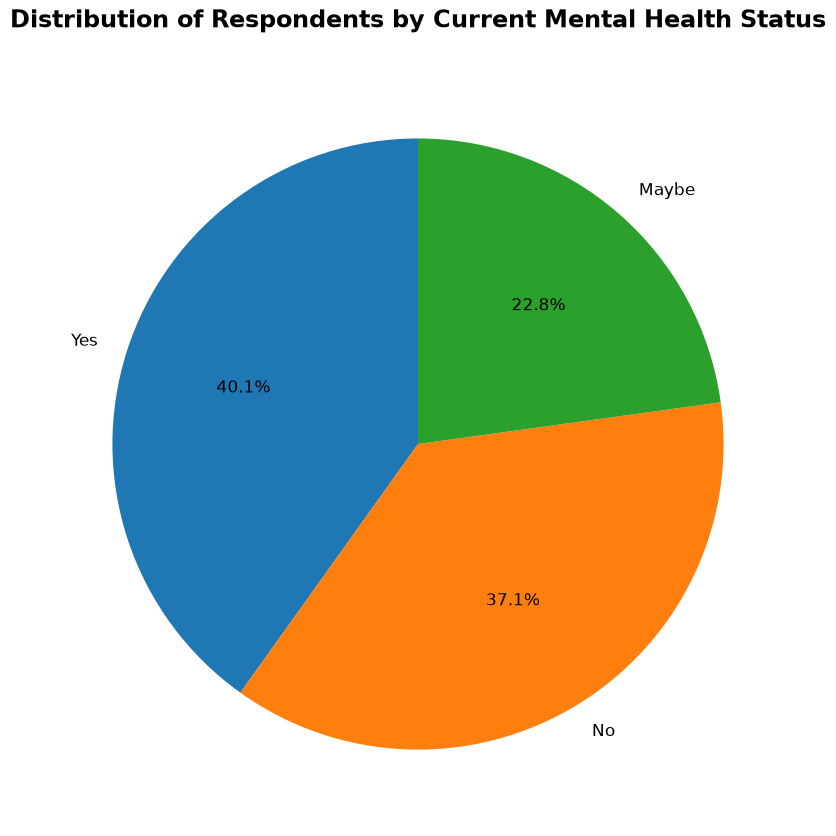

In [123]:
pd.read_csv(path)["Do you currently have a mental health disorder?"].value_counts().plot(
    kind="pie",
    figsize=(9, 9),
    autopct="%1.1f%%",
    startangle=90,
    ylabel="",
    title="Distribution of Respondents by Current Mental Health Status",
    textprops={"fontsize": 12},
)

plt.title(
    "Distribution of Respondents by Current Mental Health Status",
    fontsize=17,
    fontweight="bold",
    pad=25,
)
plt.tight_layout(pad=3)
plt.savefig(
    f"{FIGURES_PATH}/dist_of_respondents_by_current_mental_illness_status",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [124]:
pd.read_csv(path)["If yes, what condition(s) have you been diagnosed with?"].info()

<class 'pandas.Series'>
RangeIndex: 1433 entries, 0 to 1432
Series name: If yes, what condition(s) have you been diagnosed with?
Non-Null Count  Dtype
--------------  -----
568 non-null    str  
dtypes: str(1)
memory usage: 11.3 KB


In [125]:
pd.read_csv(path)["If yes, what condition(s) have you been diagnosed with?"].nunique(dropna=True)

128

In [126]:
pd.read_csv(path)["If yes, what condition(s) have you been diagnosed with?"].isna().sum()

np.int64(865)

In [150]:
round(pd.read_csv(path)["If yes, what condition(s) have you been diagnosed with?"].isna().mean() * 100, 2)

np.float64(60.36)

In [129]:
pd.read_csv(path)["If yes, what condition(s) have you been diagnosed with?"].value_counts().head(20)

If yes, what condition(s) have you been diagnosed with?
Anxiety Disorder (Generalized, Social, Phobia, etc)|Mood Disorder (Depression, Bipolar Disorder, etc)                                                                 117
Mood Disorder (Depression, Bipolar Disorder, etc)                                                                                                                     102
Anxiety Disorder (Generalized, Social, Phobia, etc)                                                                                                                    47
Anxiety Disorder (Generalized, Social, Phobia, etc)|Mood Disorder (Depression, Bipolar Disorder, etc)|Attention Deficit Hyperactivity Disorder                         26
Mood Disorder (Depression, Bipolar Disorder, etc)|Attention Deficit Hyperactivity Disorder                                                                             22
Attention Deficit Hyperactivity Disorder                                                      

In [130]:
pd.read_csv(path)["If yes, what condition(s) have you been diagnosed with?"].dropna().sample(
    min(20, pd.read_csv(path)["If yes, what condition(s) have you been diagnosed with?"].notna().sum()),
    random_state=42,
)

577     Anxiety Disorder (Generalized, Social, Phobia,...
195     Anxiety Disorder (Generalized, Social, Phobia,...
269     Anxiety Disorder (Generalized, Social, Phobia,...
534     Mood Disorder (Depression, Bipolar Disorder, etc)
1395    Anxiety Disorder (Generalized, Social, Phobia,...
1378             Eating Disorder (Anorexia, Bulimia, etc)
1138    Anxiety Disorder (Generalized, Social, Phobia,...
132     Anxiety Disorder (Generalized, Social, Phobia,...
674     Mood Disorder (Depression, Bipolar Disorder, etc)
1356    Mood Disorder (Depression, Bipolar Disorder, etc)
1107    Anxiety Disorder (Generalized, Social, Phobia,...
402     Anxiety Disorder (Generalized, Social, Phobia,...
1411                     Schizotypal Personality Disorder
302     Mood Disorder (Depression, Bipolar Disorder, e...
1291    Anxiety Disorder (Generalized, Social, Phobia,...
1081    Anxiety Disorder (Generalized, Social, Phobia,...
1387    Mood Disorder (Depression, Bipolar Disorder, etc)
469     Mood D

In [131]:
pd.read_csv(path)["If maybe, what condition(s) do you believe you have?"].info()

<class 'pandas.Series'>
RangeIndex: 1433 entries, 0 to 1432
Series name: If maybe, what condition(s) do you believe you have?
Non-Null Count  Dtype
--------------  -----
322 non-null    str  
dtypes: str(1)
memory usage: 11.3 KB


In [132]:
pd.read_csv(path)["If maybe, what condition(s) do you believe you have?"].nunique(dropna=True)

99

In [133]:
pd.read_csv(path)["If maybe, what condition(s) do you believe you have?"].isna().sum()

np.int64(1111)

In [134]:
pd.read_csv(path)["If maybe, what condition(s) do you believe you have?"].isna().mean().round(2) * 100

np.float64(78.0)

In [135]:
pd.read_csv(path)["If maybe, what condition(s) do you believe you have?"].value_counts().head(20)

If maybe, what condition(s) do you believe you have?
Mood Disorder (Depression, Bipolar Disorder, etc)                                                                                                                     55
Anxiety Disorder (Generalized, Social, Phobia, etc)|Mood Disorder (Depression, Bipolar Disorder, etc)                                                                 49
Anxiety Disorder (Generalized, Social, Phobia, etc)                                                                                                                   35
Mood Disorder (Depression, Bipolar Disorder, etc)|Attention Deficit Hyperactivity Disorder                                                                            10
Anxiety Disorder (Generalized, Social, Phobia, etc)|Mood Disorder (Depression, Bipolar Disorder, etc)|Attention Deficit Hyperactivity Disorder                        10
Attention Deficit Hyperactivity Disorder                                                              

In [136]:
pd.read_csv(path)["If maybe, what condition(s) do you believe you have?"].dropna().sample(
    min(20, pd.read_csv(path)["If maybe, what condition(s) do you believe you have?"].notna().sum()),
    random_state=42,
)

794     Mood Disorder (Depression, Bipolar Disorder, etc)
606     Anxiety Disorder (Generalized, Social, Phobia,...
886     Anxiety Disorder (Generalized, Social, Phobia,...
56      Mood Disorder (Depression, Bipolar Disorder, e...
490     Anxiety Disorder (Generalized, Social, Phobia,...
535     Mood Disorder (Depression, Bipolar Disorder, etc)
1124    Mood Disorder (Depression, Bipolar Disorder, etc)
736     Anxiety Disorder (Generalized, Social, Phobia,...
998     Mood Disorder (Depression, Bipolar Disorder, etc)
1385    Anxiety Disorder (Generalized, Social, Phobia,...
883     Anxiety Disorder (Generalized, Social, Phobia,...
444     Anxiety Disorder (Generalized, Social, Phobia,...
1260    Personality Disorder (Borderline, Antisocial, ...
411     Mood Disorder (Depression, Bipolar Disorder, etc)
840     Mood Disorder (Depression, Bipolar Disorder, etc)
1200    Anxiety Disorder (Generalized, Social, Phobia,...
579     Mood Disorder (Depression, Bipolar Disorder, e...
379     Anxiet

In [137]:
pd.read_csv(path)[
    "If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?"
].info()

<class 'pandas.Series'>
RangeIndex: 1433 entries, 0 to 1432
Series name: If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?
Non-Null Count  Dtype
--------------  -----
1433 non-null   str  
dtypes: str(1)
memory usage: 11.3 KB


In [138]:
pd.read_csv(path)[
    "If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?"
].value_counts(dropna=False)

If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?
Not applicable to me    557
Sometimes               369
Rarely                  322
Never                   120
Often                    65
Name: count, dtype: int64

In [139]:
pd.read_csv(path)[
    "If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?"
].isna().sum()

np.int64(0)

In [140]:
pd.read_csv(path)[
    "If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?"
].value_counts(normalize=True, dropna=False).mul(100).round(2)

If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?
Not applicable to me    38.87
Sometimes               25.75
Rarely                  22.47
Never                    8.37
Often                    4.54
Name: proportion, dtype: float64

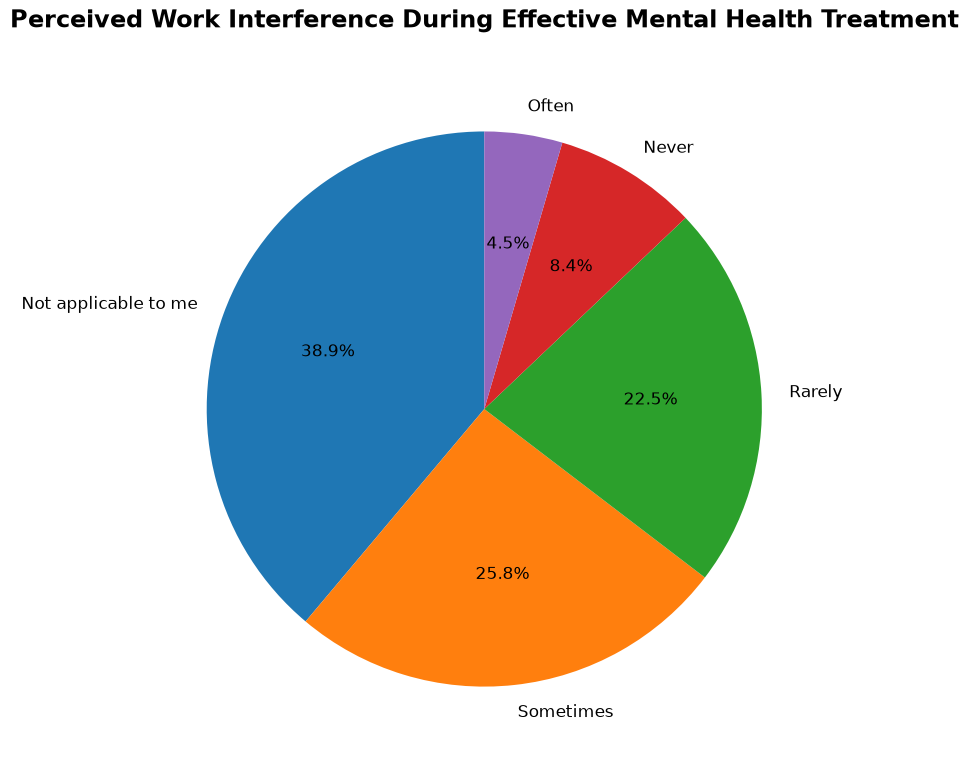

In [141]:
pd.read_csv(path)[
    "If you have a mental health issue, do you feel that it interferes with your work when being treated effectively?"
].value_counts().plot(
    kind="pie",
    figsize=(9, 9),
    autopct="%1.1f%%",
    startangle=90,
    ylabel="",
    title="Perceived Work Interference During Effective Mental Health Treatment",
    textprops={"fontsize": 12},
)

plt.title(
    "Perceived Work Interference During Effective Mental Health Treatment",
    fontsize=17,
    fontweight="bold",
    pad=25,
)
plt.tight_layout(pad=3)
plt.savefig(
    f"{FIGURES_PATH}/work_interference_during_effective_treatment.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [142]:
pd.read_csv(path)["Do you believe your productivity is ever affected by a mental health issue?"].info()

<class 'pandas.Series'>
RangeIndex: 1433 entries, 0 to 1432
Series name: Do you believe your productivity is ever affected by a mental health issue?
Non-Null Count  Dtype
--------------  -----
287 non-null    str  
dtypes: str(1)
memory usage: 11.3 KB


In [143]:
pd.read_csv(path)[
    "Do you believe your productivity is ever affected by a mental health issue?"
].value_counts(dropna=False)

Do you believe your productivity is ever affected by a mental health issue?
NaN                     1146
Yes                      204
Unsure                    38
Not applicable to me      31
No                        14
Name: count, dtype: int64

In [149]:
round(pd.read_csv(path)[
    "Do you believe your productivity is ever affected by a mental health issue?"
].isna().mean() * 100, 2)

np.float64(79.97)

In [147]:
pd.read_csv(path)[
    "Do you believe your productivity is ever affected by a mental health issue?"
].value_counts(normalize=True, dropna=False).mul(100).round(2)

Do you believe your productivity is ever affected by a mental health issue?
NaN                     79.97
Yes                     14.24
Unsure                   2.65
Not applicable to me     2.16
No                       0.98
Name: proportion, dtype: float64

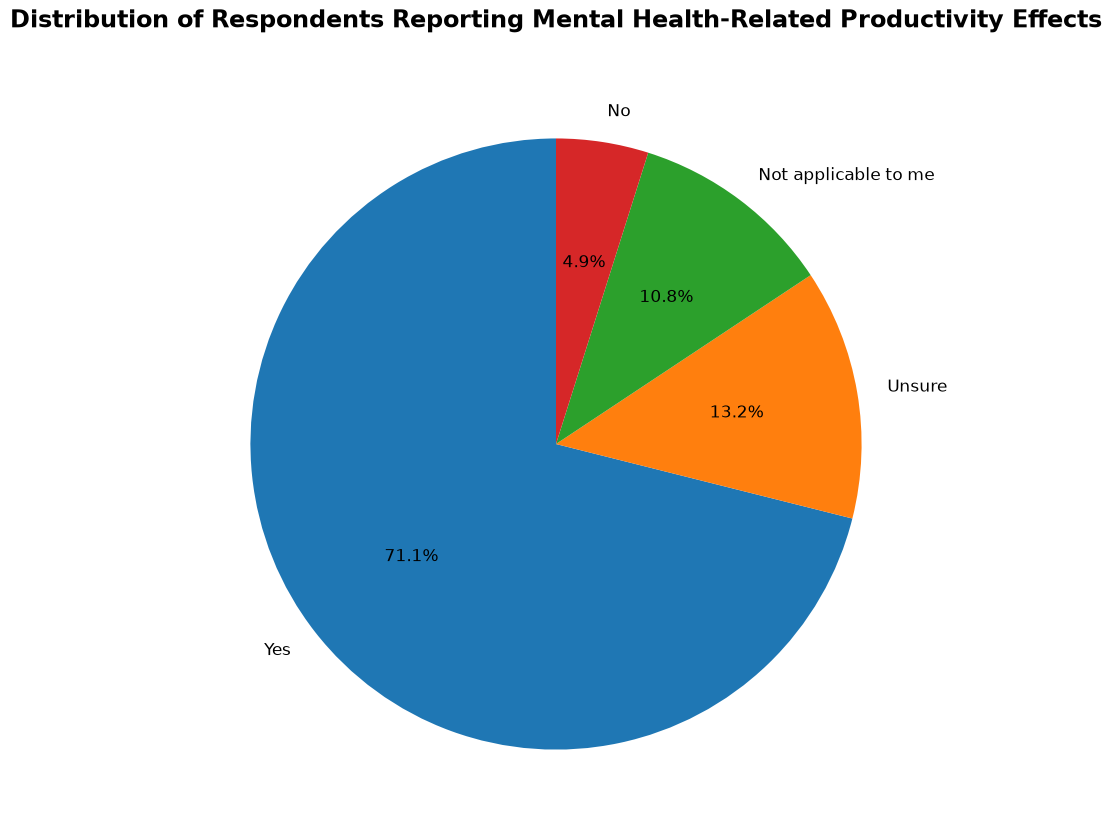

In [151]:
pd.read_csv(path)["Do you believe your productivity is ever affected by a mental health issue?"].value_counts().plot(
    kind="pie",
    figsize=(9, 9),
    autopct="%1.1f%%",
    startangle=90,
    ylabel="",
    title="Distribution of Respondents Reporting Mental Health-Related Productivity Effects",
    textprops={"fontsize": 12},
)

plt.title(
    "Distribution of Respondents Reporting Mental Health-Related Productivity Effects",
    fontsize=17,
    fontweight="bold",
    pad=25,
)
plt.tight_layout(pad=3)
plt.savefig(
    f"{FIGURES_PATH}/mental_health_related_productivity_effects.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [152]:
pd.read_csv(path)[
    "If yes, what percentage of your work time (time performing primary or "
    "secondary job functions) is affected by a mental health issue?"
].info()

<class 'pandas.Series'>
RangeIndex: 1433 entries, 0 to 1432
Series name: If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?
Non-Null Count  Dtype
--------------  -----
204 non-null    str  
dtypes: str(1)
memory usage: 11.3 KB


In [153]:
pd.read_csv(path)[
    "If yes, what percentage of your work time (time performing primary or "
    "secondary job functions) is affected by a mental health issue?"
].value_counts(dropna=False)

If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?
NaN        1229
1-25%        92
26-50%       72
51-75%       26
76-100%      14
Name: count, dtype: int64

In [154]:
round(pd.read_csv(path)[
    "If yes, what percentage of your work time (time performing primary or "
    "secondary job functions) is affected by a mental health issue?"
].isna().mean() * 100, 2)

np.float64(85.76)

In [155]:
round(pd.read_csv(path)[
    "If yes, what percentage of your work time (time performing primary or "
    "secondary job functions) is affected by a mental health issue?"
].value_counts(normalize=True, dropna=False) * 100, 2)

If yes, what percentage of your work time (time performing primary or secondary job functions) is affected by a mental health issue?
NaN        85.76
1-25%       6.42
26-50%      5.02
51-75%      1.81
76-100%     0.98
Name: proportion, dtype: float64

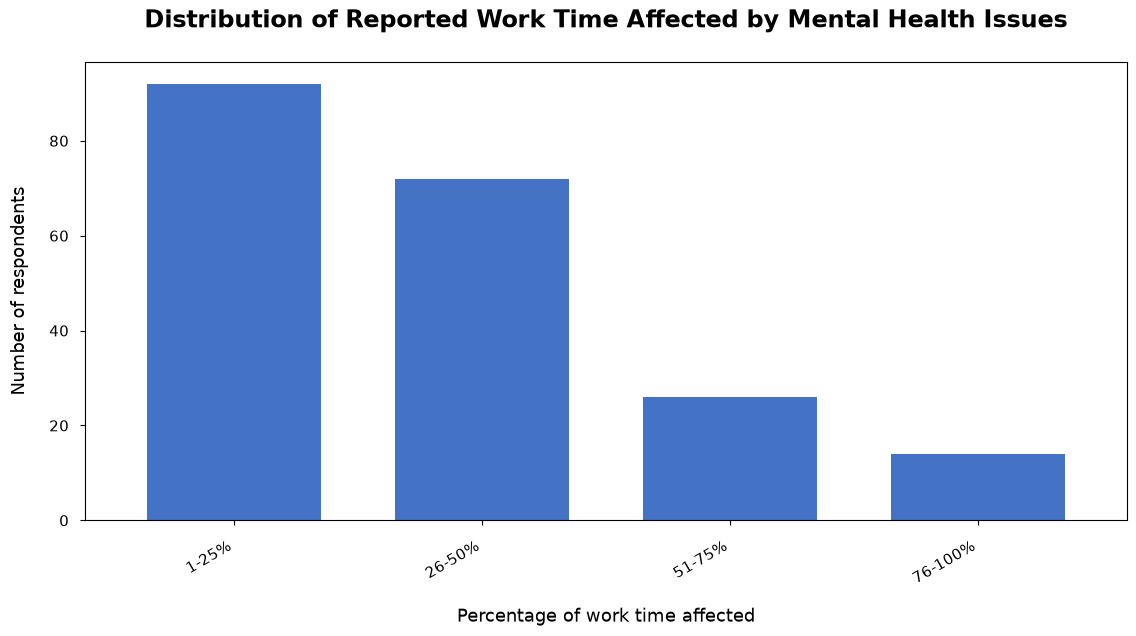

In [157]:
pd.read_csv(path)[
    "If yes, what percentage of your work time (time performing primary or "
    "secondary job functions) is affected by a mental health issue?"
].value_counts().plot(
    kind="bar",
    figsize=(12, 7),
    color="#4472C4",
    width=0.7,
    title="Distribution of Reported Work Time Affected by Mental Health Issues",
    xlabel="Percentage of work time affected",
    ylabel="Number of respondents",
)

plt.title(
    "Distribution of Reported Work Time Affected by Mental Health Issues",
    fontsize=17,
    fontweight="bold",
    pad=25,
)
plt.xlabel("Percentage of work time affected", fontsize=13, labelpad=15)
plt.ylabel("Number of respondents", fontsize=13, labelpad=15)
plt.xticks(rotation=30, ha="right", fontsize=11)
plt.yticks(fontsize=11)
plt.tick_params(axis="x", pad=10)
plt.tick_params(axis="y", pad=8)
plt.tight_layout(pad=3)
plt.savefig(
    f"{FIGURES_PATH}/affected_reported_work_time.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [158]:
pd.read_csv(path)[
    "Have you observed or experienced an unsupportive or badly handled "
    "response to a mental health issue in your current or previous workplace?"
].info()

<class 'pandas.Series'>
RangeIndex: 1433 entries, 0 to 1432
Series name: Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?
Non-Null Count  Dtype
--------------  -----
1344 non-null   str  
dtypes: str(1)
memory usage: 11.3 KB


In [159]:
pd.read_csv(path)[
    "Have you observed or experienced an unsupportive or badly handled "
    "response to a mental health issue in your current or previous workplace?"
].value_counts(dropna=False)

Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?
No                    567
Maybe/Not sure        346
Yes, I observed       264
Yes, I experienced    167
NaN                    89
Name: count, dtype: int64

In [160]:
round(pd.read_csv(path)[
    "Have you observed or experienced an unsupportive or badly handled "
    "response to a mental health issue in your current or previous workplace?"
].isna().mean() * 100, 2)

np.float64(6.21)

In [161]:
pd.read_csv(path)[
    "Have you observed or experienced an unsupportive or badly handled "
    "response to a mental health issue in your current or previous workplace?"
].value_counts(normalize=True, dropna=False).mul(100).round(2)

Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?
No                    39.57
Maybe/Not sure        24.15
Yes, I observed       18.42
Yes, I experienced    11.65
NaN                    6.21
Name: proportion, dtype: float64

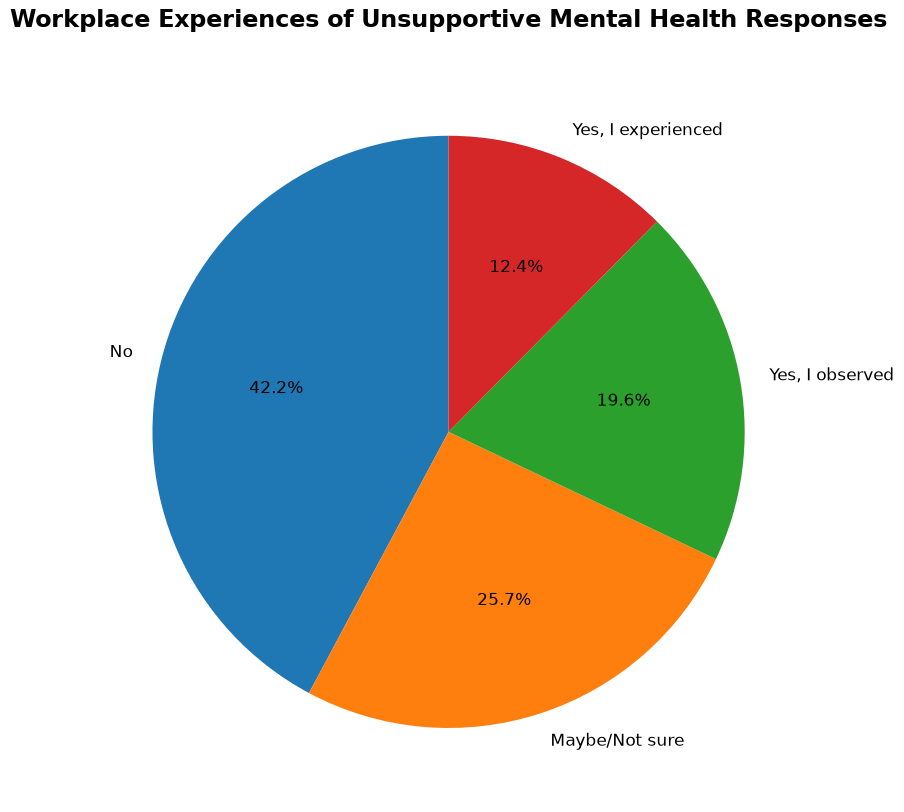

In [162]:
pd.read_csv(path)[
    "Have you observed or experienced an unsupportive or badly handled response "
    "to a mental health issue in your current or previous workplace?"
].value_counts().plot(
    kind="pie",
    figsize=(9, 9),
    autopct="%1.1f%%",
    startangle=90,
    ylabel="",
    title="Workplace Experiences of Unsupportive Mental Health Responses",
    textprops={"fontsize": 12},
)

plt.title(
    "Workplace Experiences of Unsupportive Mental Health Responses",
    fontsize=17,
    fontweight="bold",
    pad=25,
)
plt.tight_layout(pad=3)
plt.savefig(
    f"{FIGURES_PATH}/wokplace_exp_of_unsupportive_mental_health.response.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [164]:
pd.read_csv(path)[
    "Have your observations of how another individual who discussed a mental "
    "health disorder made you less likely to reveal a mental health issue yourself in your current workplace?"
].info()

<class 'pandas.Series'>
RangeIndex: 1433 entries, 0 to 1432
Series name: Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?
Non-Null Count  Dtype
--------------  -----
657 non-null    str  
dtypes: str(1)
memory usage: 11.3 KB


In [165]:
pd.read_csv(path)[
    "Have your observations of how another individual who discussed a mental health disorder "
    "made you less likely to reveal a mental health issue yourself in your current workplace?"
].value_counts(dropna=False)

Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?
NaN      776
Yes      246
No       234
Maybe    177
Name: count, dtype: int64

In [166]:
round(pd.read_csv(path)[
    "Have your observations of how another individual who discussed a mental health disorder "
    "made you less likely to reveal a mental health issue yourself in your current workplace?"
].isna().mean() * 100, 2)

np.float64(54.15)

In [167]:
round(pd.read_csv(path)[
    "Have your observations of how another individual who discussed a mental health disorder "
    "made you less likely to reveal a mental health issue yourself in your current workplace?"
].value_counts(normalize=True, dropna=False) * 100, 2)

Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?
NaN      54.15
Yes      17.17
No       16.33
Maybe    12.35
Name: proportion, dtype: float64

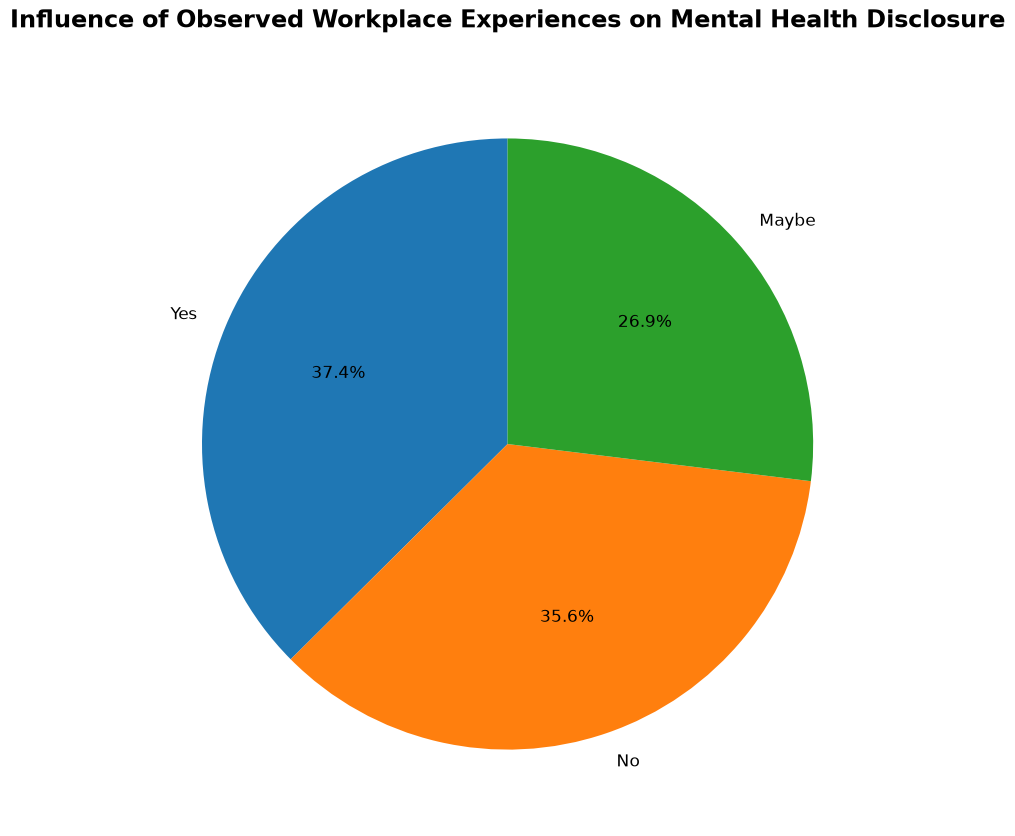

In [169]:
pd.read_csv(path)[
    "Have your observations of how another individual who discussed a mental health disorder "
    "made you less likely to reveal a mental health issue yourself in your current workplace?"
].value_counts().plot(
    kind="pie",
    figsize=(9, 9),
    autopct="%1.1f%%",
    startangle=90,
    ylabel="",
    title="Influence of Observed Workplace Experiences on Mental Health Disclosure",
    textprops={"fontsize": 12},
)

plt.title(
    "Influence of Observed Workplace Experiences on Mental Health Disclosure",
    fontsize=17,
    fontweight="bold",
    pad=25,
)
plt.tight_layout(pad=3)
plt.savefig(
    f"{FIGURES_PATH}/influence_of_observed_workplace_experiences.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [173]:
pd.crosstab(
    pd.read_csv(path)[
        "Have you observed or experienced an unsupportive or badly handled response "
        "to a mental health issue in your current or previous workplace?"
    ],
    pd.read_csv(path)[
        "Have your observations of how another individual who discussed a mental health "
        "disorder made you less likely to reveal a mental health issue yourself in your current workplace?"
    ],
    margins=True,
)

Have your observations of how another individual who discussed a mental health disorder made you less likely to reveal a mental health issue yourself in your current workplace?,Maybe,No,Yes,All
Have you observed or experienced an unsupportive or badly handled response to a mental health issue in your current or previous workplace?,,,,
Maybe/Not sure,82,137,53,272
"Yes, I experienced",33,41,65,139
"Yes, I observed",62,56,128,246
All,177,234,246,657
